In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
from gprofiler import GProfiler
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3


from datetime import date
import sys
sys.path.append("/storage/groups/ml01/workspace/jan.domke/Code/")
import scib_excerpts
import plot_ma
import gprofiler_custom_LISA

In [2]:
#Import color palette to get consistent colors across figures
import pickle  
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

In [3]:
new_reds = plot_ma.shiftedColorMap(plot_ma.matplotlib.cm.Reds, midpoint=0.7, name='shifted')

In [5]:
# Get date for naming of plots
today = date.today()
date = today.strftime("%d_%m_%Y")

In [6]:
# Specify studies and datasets with IPF data
ipf_studies = ["Kaminski_2020", "Banovich_Kropski_2020", "Misharin_Budinger_2018", "Sheppard_2020"]
ipf_datasets = ipf_studies

In [7]:
# Import datasets with Milos differential abundance values for k = 50
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_scarches_labeled_milo.h5ad")

In [8]:
# Import milo logFC values calculated with k = 150
denovo_recalc_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/ipf_scarches_labeled_logFC.h5ad")

In [9]:
# Import milo logFC values for disease/healthy calculated with k = 150
denovo_recalc_logFC_avg_disease_healthy = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/Disease_Healthy/ipf_denovo_recalc_logFC_disease_healthy.h5ad")
scarches_unlabeled_logFC_avg_disease_healthy = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/Disease_Healthy/ipf_scarches_unlabeled_logFC_disease_healthy.h5ad")

denovo_recalc.obs["logFC_avg_disease_healthy"] = denovo_recalc_logFC_avg_disease_healthy
scarches_unlabeled.obs["logFC_avg_disease_healthy"] = scarches_unlabeled_logFC_avg_disease_healthy

In [10]:
# Update milo logFC values with new ones calculated with k = 150
denovo_recalc.obs.logFC_avg = denovo_recalc_logFC_avg
denovo_ref.obs.logFC_avg = denovo_ref_logFC_avg
scarches_unlabeled.obs.logFC_avg = scarches_unlabeled_logFC_avg
scarches_labeled.obs.logFC_avg = scarches_labeled_logFC_avg

In [11]:
# Show how many cells,datasets,studies are included in reference and query
ncells = denovo_recalc.obs.groupby("origin").size()
ndata = denovo_recalc.obs.groupby("origin").dataset.nunique()
nstudy = denovo_recalc.obs.groupby("origin").study.nunique()

names = ["cells", "datasets", "studies"]
counts_ipf = pd.concat([ncells,ndata,nstudy],axis=1)
counts_ipf = counts_ipf.rename({0:"cells"},axis=1)
counts_ipf

,cells,dataset,study
origin,,,
query,374495,4,4
reference,584884,14,11


In [12]:
# rename ipf query studies which are also included partly in healthy reference to differenciate between those
denovo_recalc.obs["study"] = denovo_recalc.obs["study"].astype("string")
denovo_recalc.obs.loc[(denovo_recalc.obs.origin == "query") & 
                      (denovo_recalc.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = denovo_recalc.obs.loc[(denovo_recalc.obs.origin == "query") & 
                      (denovo_recalc.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
denovo_recalc.obs["study"] = denovo_recalc.obs["study"].astype("category")

denovo_ref.obs["study"] = denovo_ref.obs["study"].astype("string")
denovo_ref.obs.loc[(denovo_ref.obs.origin == "query") & 
                      (denovo_ref.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = denovo_ref.obs.loc[(denovo_ref.obs.origin == "query") & 
                      (denovo_ref.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
denovo_ref.obs["study"] = denovo_ref.obs["study"].astype("category")

scarches_unlabeled.obs["study"] = scarches_unlabeled.obs["study"].astype("string")
scarches_unlabeled.obs.loc[(scarches_unlabeled.obs.origin == "query") & 
                      (scarches_unlabeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = scarches_unlabeled.obs.loc[(scarches_unlabeled.obs.origin == "query") & 
                      (scarches_unlabeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
scarches_unlabeled.obs["study"] = scarches_unlabeled.obs["study"].astype("category")

scarches_labeled.obs["study"] = scarches_labeled.obs["study"].astype("string")
scarches_labeled.obs.loc[(scarches_labeled.obs.origin == "query") & 
                      (scarches_labeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = scarches_labeled.obs.loc[(scarches_labeled.obs.origin == "query") & 
                      (scarches_labeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
scarches_labeled.obs["study"] = scarches_labeled.obs["study"].astype("category")

In [13]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("string")
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("category")

In [14]:
# Classify conditions in "Healthy" and "Disease"
scarches_unlabeled.obs["condition_cat"] = ["Disease" if cond in ["IPF"] else "Healthy" for cond in scarches_unlabeled.obs["condition"]]
denovo_recalc.obs["condition_cat"] = ["Disease" if cond in ["IPF"] else "Healthy" for cond in denovo_recalc.obs["condition"]]
denovo_ref.obs["condition_cat"] = ["Disease" if cond in ["IPF"] else "Healthy" for cond in denovo_ref.obs["condition"]]
scarches_labeled.obs["condition_cat"] = ["Disease" if cond in ["IPF"] else "Healthy" for cond in scarches_labeled.obs["condition"]]

In [15]:
# Calculate all different combinations of logFC values we want to compare
scarches_unlabeled.obs["diff_denovo_recalc"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_unlabeled.obs["diff_denovo_ref"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_unlabeled.obs["diff_scArches_labeled"] = abs(scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_recalc"] = abs(scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_ref"] = abs(scarches_labeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_labeled.obs["diff_scArches_unlabeled"] = abs(scarches_labeled.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_ref.obs["diff_denovo_recalc"] = abs(denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
denovo_ref.obs["diff_scArches_labeled"] = abs(denovo_ref.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_ref.obs["diff_scArches_unlabeled"] = abs(denovo_ref.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_unlabeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_labeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_recalc.obs["diff_denovo_ref"] = abs(denovo_recalc.obs.logFC_avg - denovo_ref.obs.logFC_avg)

In [16]:
# Calculate all different combinations of logFC values we want to compare for diseae/healthy
scarches_unlabeled.obs["diff_denovo_recalc_disease_healthy"] = abs(scarches_unlabeled.obs.logFC_avg_disease_healthy - denovo_recalc.obs.logFC_avg_disease_healthy)
denovo_recalc.obs["diff_scArches_unlabeled_disease_healthy"] = abs(denovo_recalc.obs.logFC_avg_disease_healthy - scarches_unlabeled.obs.logFC_avg_disease_healthy)

In [17]:
# Delete any left color assignments
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']

In [18]:
scarches_unlabeled_plot = sc.pp.subsample(scarches_unlabeled, fraction=1., copy=True)
scarches_labeled_plot = sc.pp.subsample(scarches_labeled, fraction=1., copy=True)
denovo_ref_plot = sc.pp.subsample(denovo_ref, fraction=1., copy=True)
denovo_recalc_plot = sc.pp.subsample(denovo_recalc, fraction=1., copy=True)

... storing 'condition_cat' as categorical


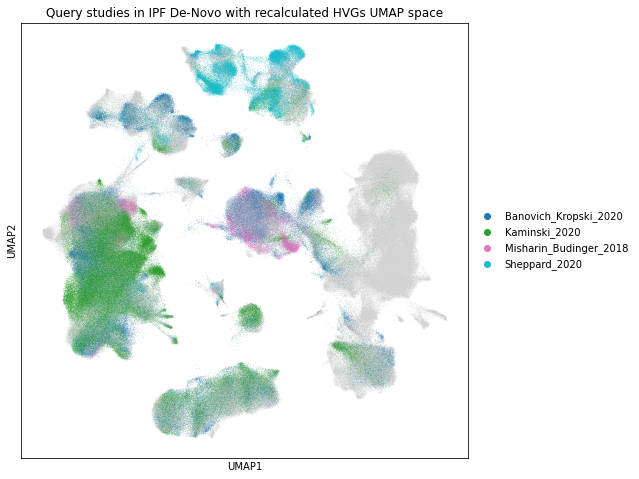

In [15]:
sc.pl.umap(denovo_recalc_plot, color="study",  size = 0.5, sort_order = False, groups = ipf_studies, palette="tab10",
          title = "Query studies in IPF De-Novo with recalculated HVGs UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

... storing 'condition_cat' as categorical


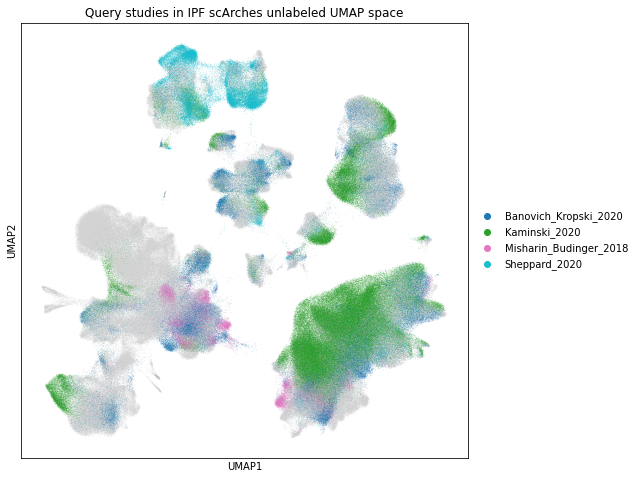

In [16]:
sc.pl.umap(scarches_unlabeled_plot, color="study",  size = 0.5, sort_order = False, groups = ipf_studies, palette="tab10",
          title = "Query studies in IPF scArches unlabeled UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

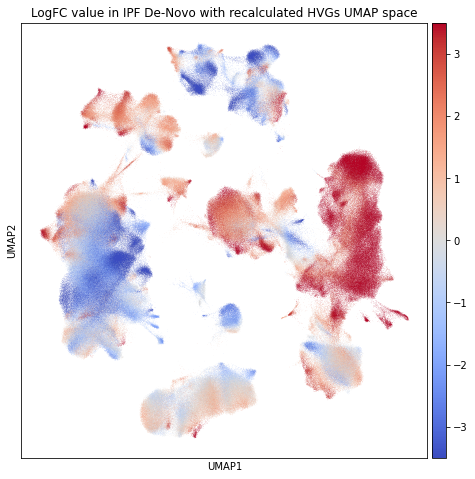

In [35]:
sc.pl.umap(denovo_recalc_plot, color = "logFC_avg", color_map = "coolwarm", vmin = "-3.5", vmax = "3.5", size = 0.3, sort_order = False,
          title = "LogFC value in IPF De-Novo with recalculated HVGs UMAP space",
          save = f"_ipf_denovo_recalc_logFC_{date}.png")

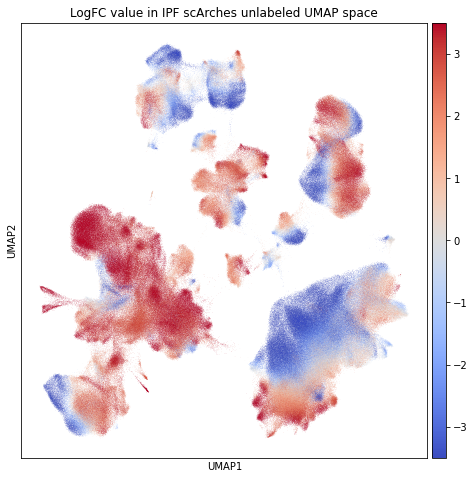

In [36]:
sc.pl.umap(scarches_unlabeled_plot, color="logFC_avg", color_map = "coolwarm", vmin = "-3.5", vmax = "3.5", size = 0.3, sort_order = False,
          title = "LogFC value in IPF scArches unlabeled UMAP space",
          save = f"_ipf_scarches_unlabeled_logFC_{date}.png")

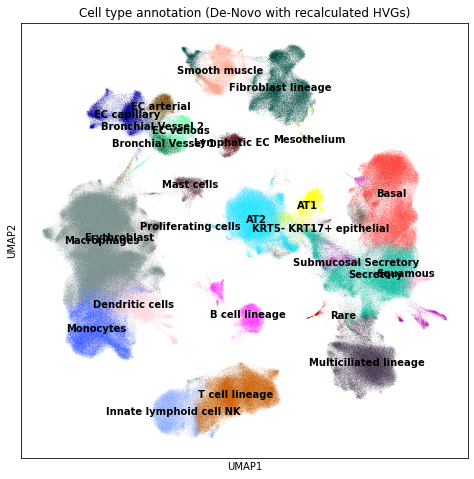

In [24]:
sc.pl.umap(denovo_recalc_plot, color = "C_scANVI", palette = colordict, legend_loc = "on data", size = 0.3, sort_order = False,
          title = "Cell type annotation (De-Novo with recalculated HVGs)",
          save = f"_ipf_denovo_recalc_annotation_{date}.png")

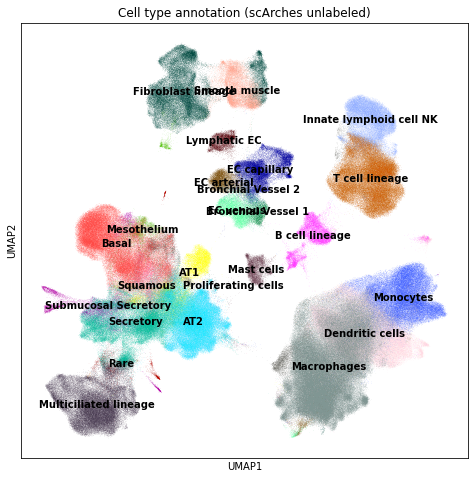

In [25]:
sc.pl.umap(scarches_unlabeled_plot, color = "C_scArches", palette = colordict, legend_loc = "on data", size = 0.3, sort_order = False,
          title = "Cell type annotation (scArches unlabeled)",
          save = f"_ipf_scarches_unlabeled_annotation_{date}.png")

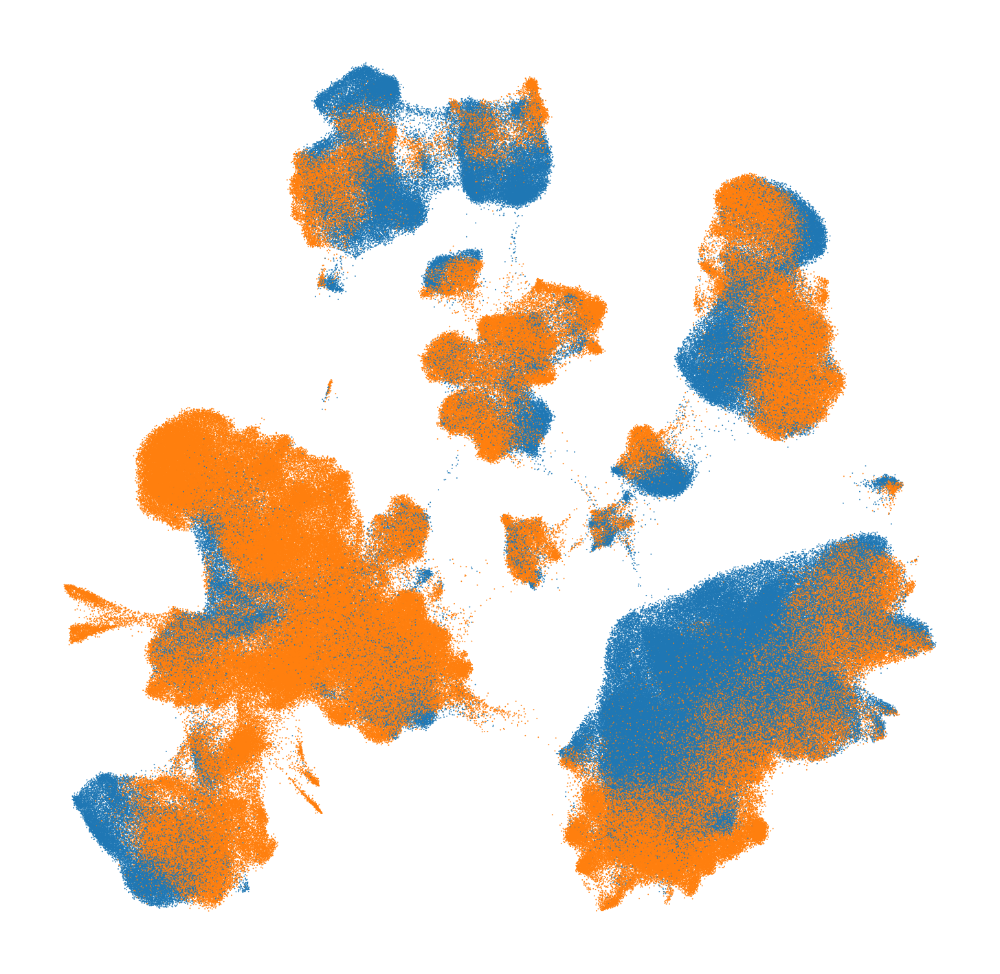

In [24]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="origin", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False, legend_loc=None,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_ipf_extension_origin.png")

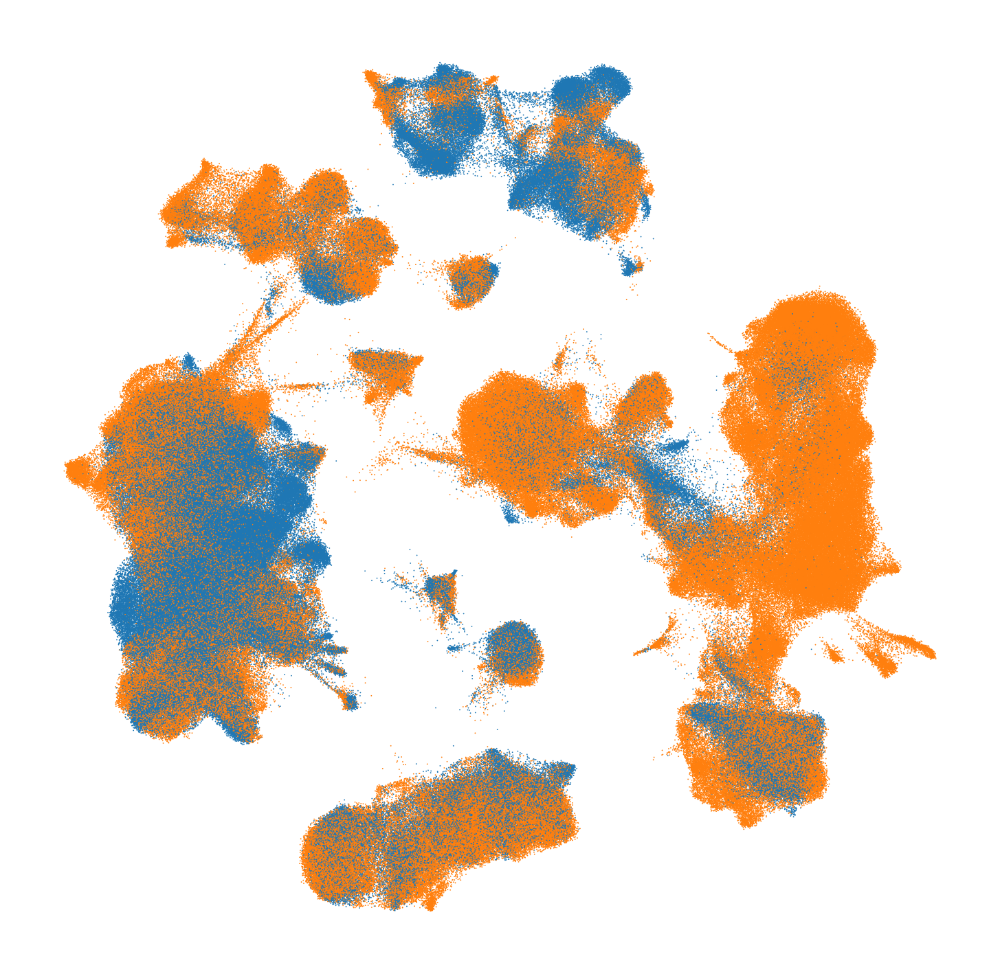

In [25]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="origin", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False, legend_loc=None,
                   title="")
    plt.savefig("figures/scANVI_ipf_extension_origin.png")

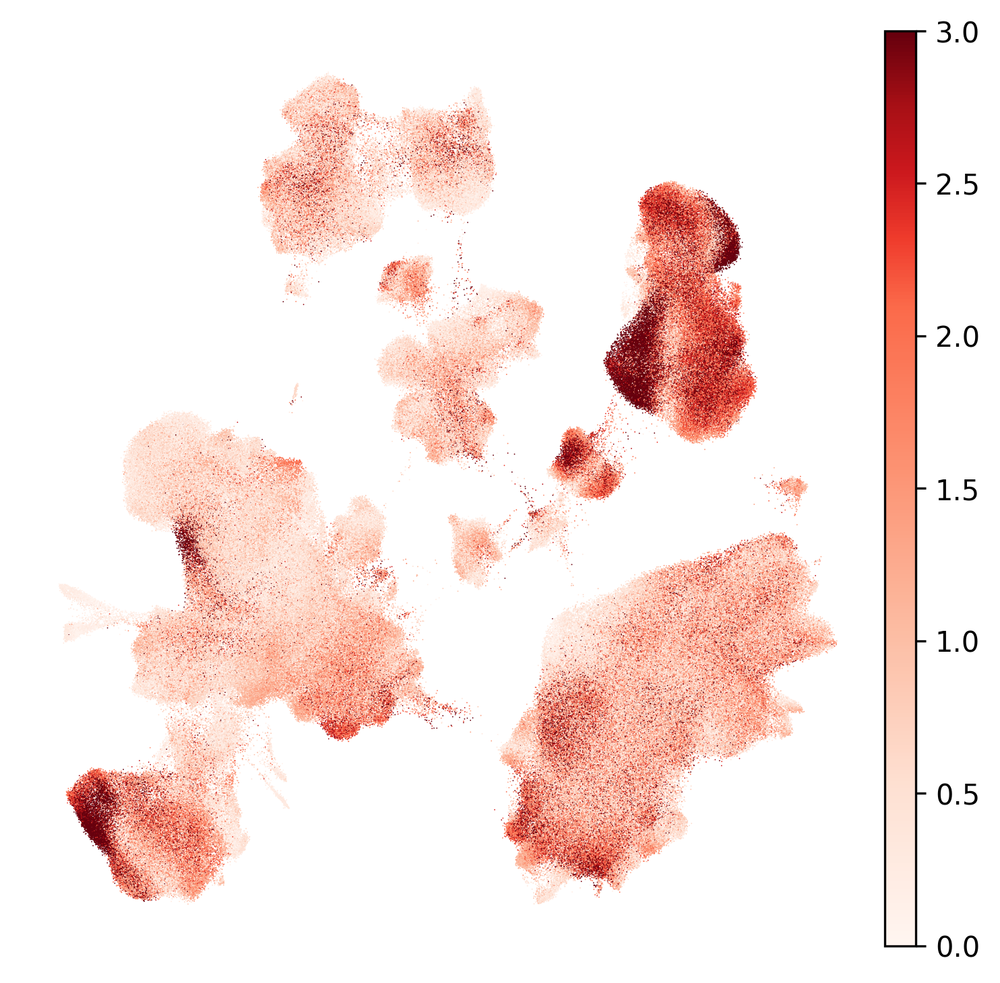

In [26]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="diff_denovo_recalc", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_ipf_extension_milo.png")

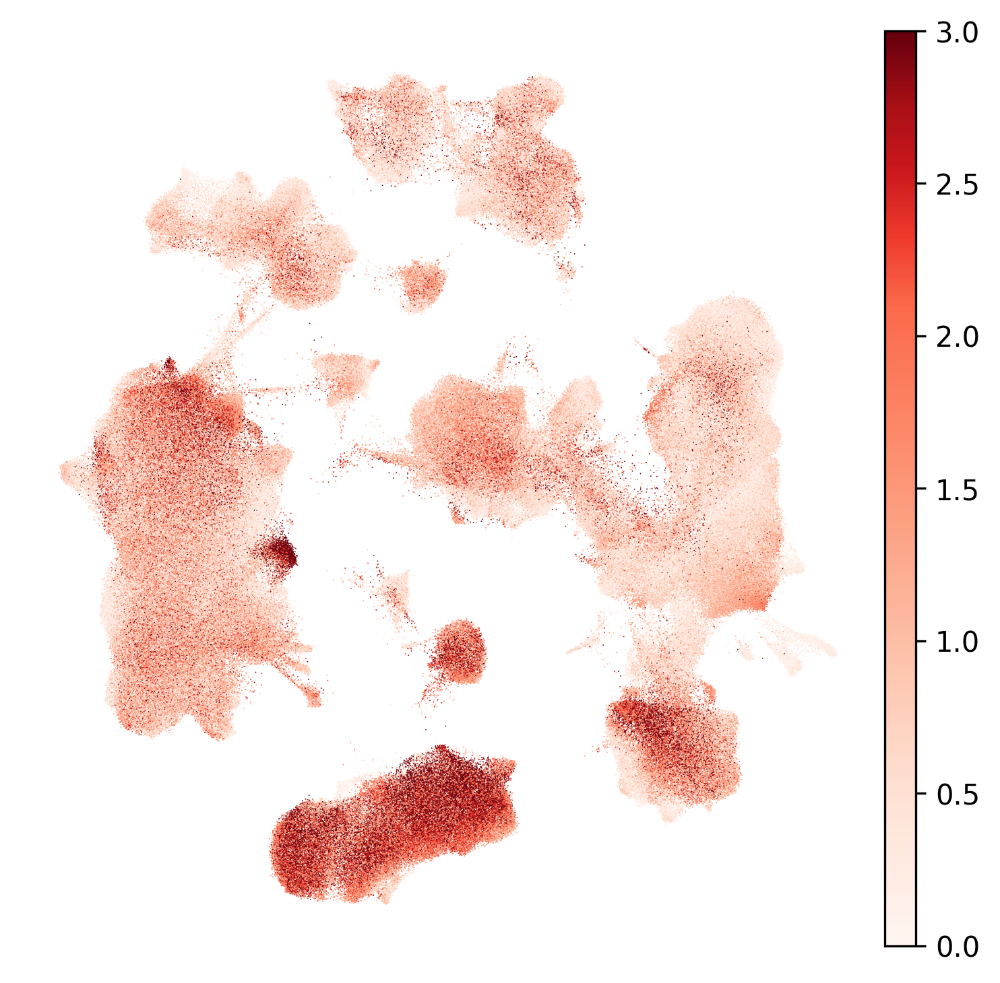

In [27]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="diff_scArches_unlabeled", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    plt.savefig("figures/scANVI_ipf_extension_milo.png")

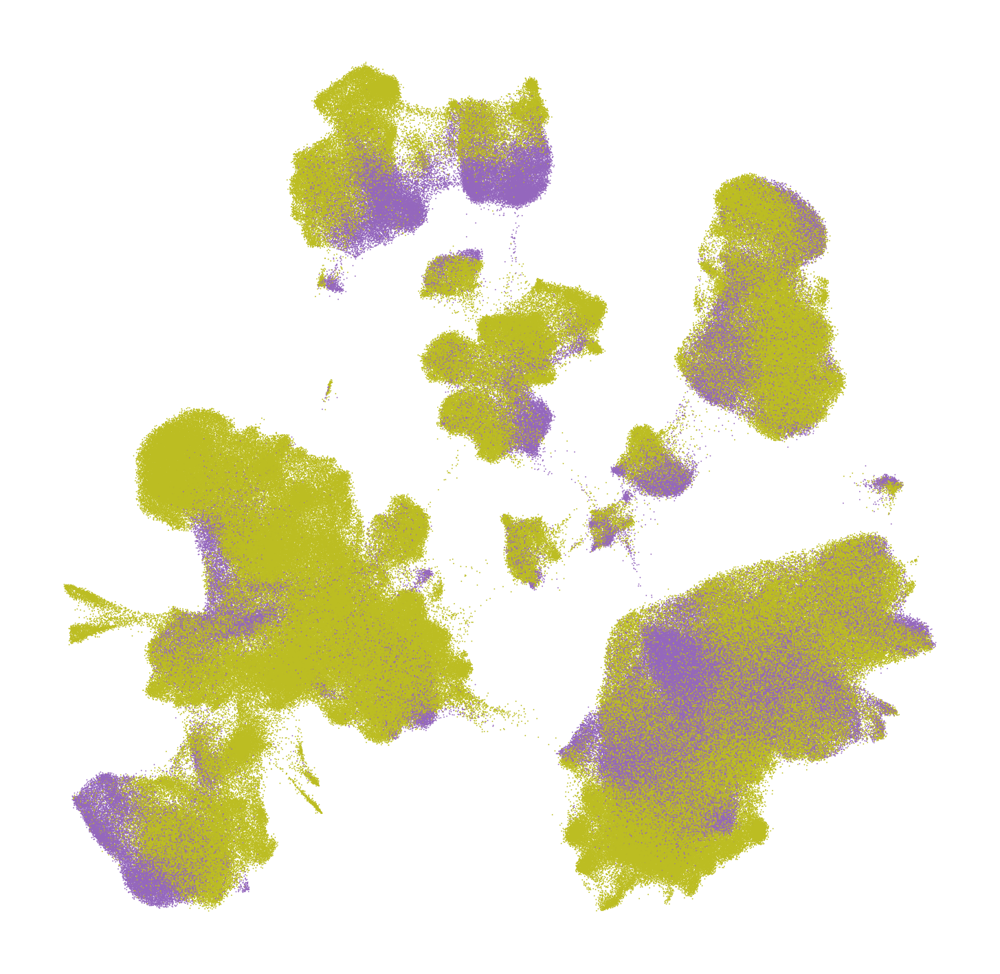

In [29]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="condition_cat", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds, legend_loc=False,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_ipf_extension_condition.png")

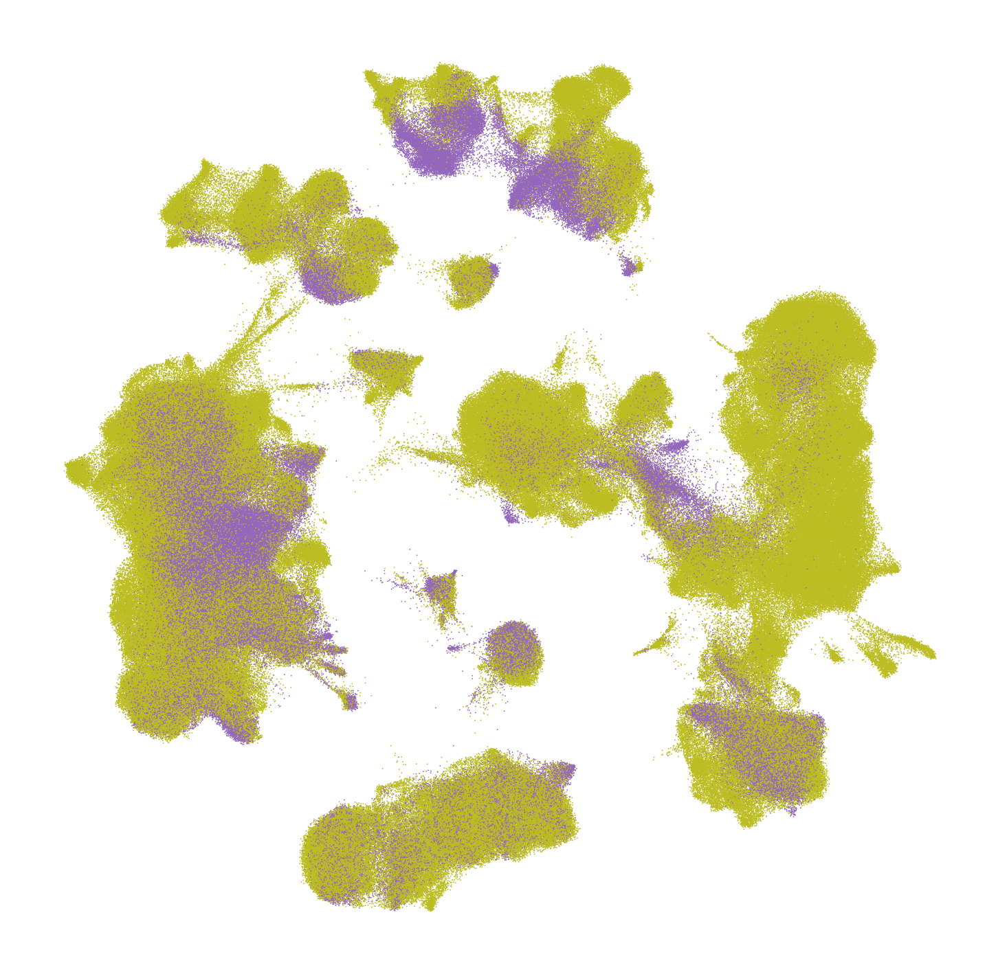

In [30]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="condition_cat", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds, legend_loc=False,
                   title="")
    plt.savefig("figures/scANVI_ipf_extension_condition.png")

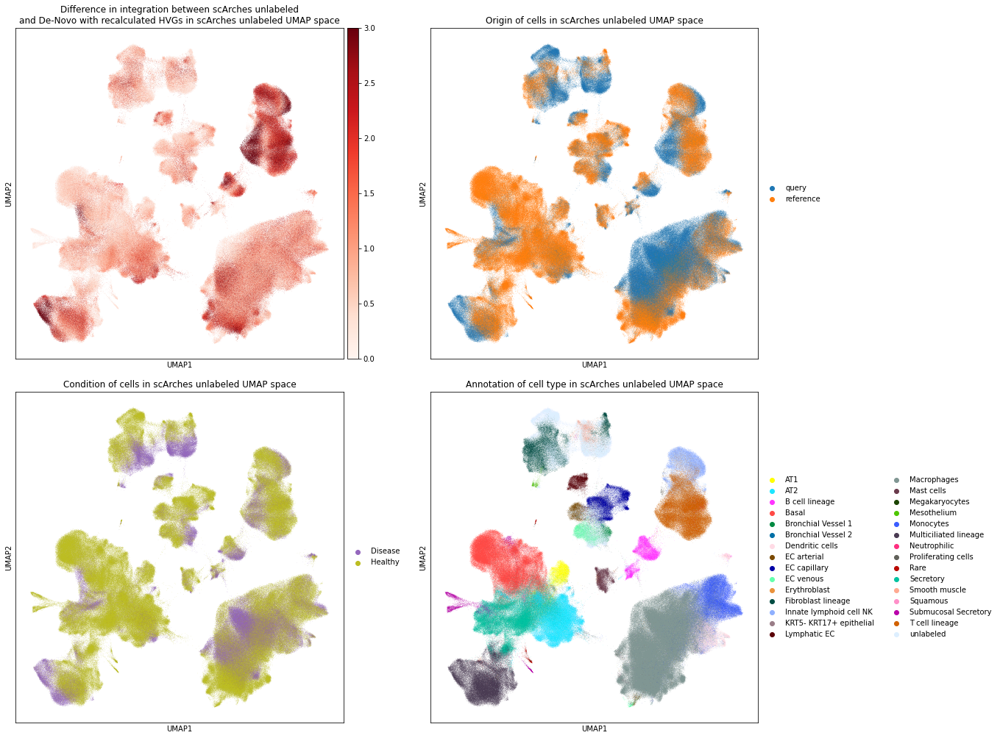

In [39]:
sc.pl.umap(scarches_unlabeled_plot, color = ["diff_denovo_recalc", "origin", "condition_cat", "scanvi_label_original"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save = f"_ipf_scarches_unlabeled_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in scArches unlabeled UMAP space",
                  "Origin of cells in scArches unlabeled UMAP space",
                  "Condition of cells in scArches unlabeled UMAP space",
                  "Annotation of cell type in scArches unlabeled UMAP space"])

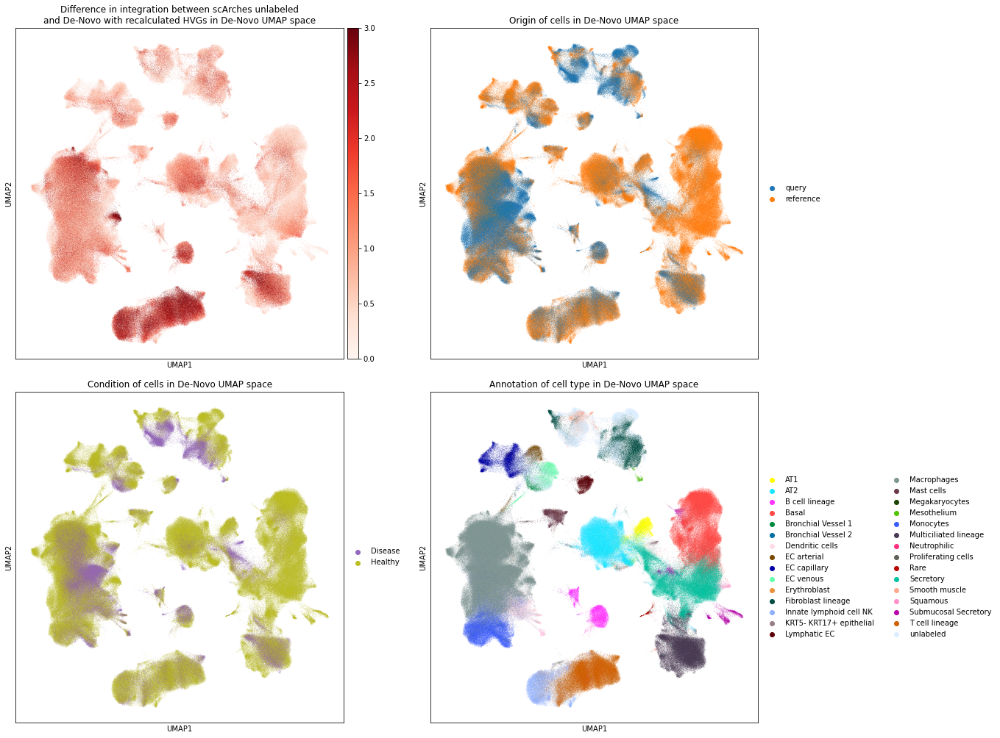

In [40]:
sc.pl.umap(denovo_recalc_plot, color = ["diff_scArches_unlabeled", "origin", "condition_cat", "scanvi_label"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save= f"_ipf_denovo_recalc_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in De-Novo UMAP space",
                  "Origin of cells in De-Novo UMAP space",
                  "Condition of cells in De-Novo UMAP space",
                  "Annotation of cell type in De-Novo UMAP space"])

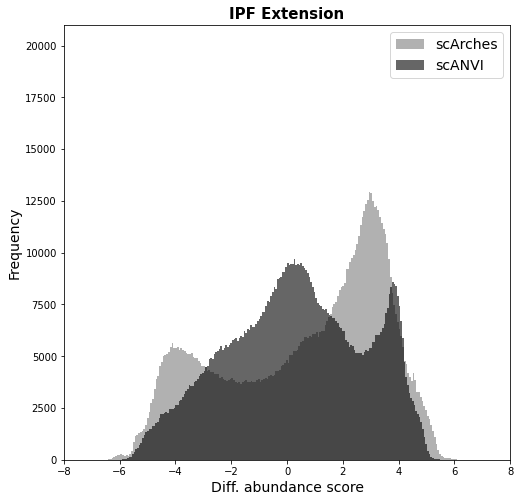

In [19]:
plt.hist(scarches_unlabeled.obs.logFC_avg, bins=200, color = "darkgrey",alpha=0.9, label="scArches")
plt.hist(denovo_recalc.obs.logFC_avg, bins=200, color = "black",alpha=0.6, label="scANVI")
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("IPF Extension",size=15,fontweight="bold")
plt.xlabel("Diff. abundance score",size=14)
plt.ylabel("Frequency",size=14)
plt.legend(loc='upper right',prop={'size': 14})
plt.grid(False)
plt.savefig("figures/ipf_extension_DA_score_distr.png", dpi=300)

### 1.1 Compare with Control Group (scANVI with reference HVGs)

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'condition_cat' as categorical


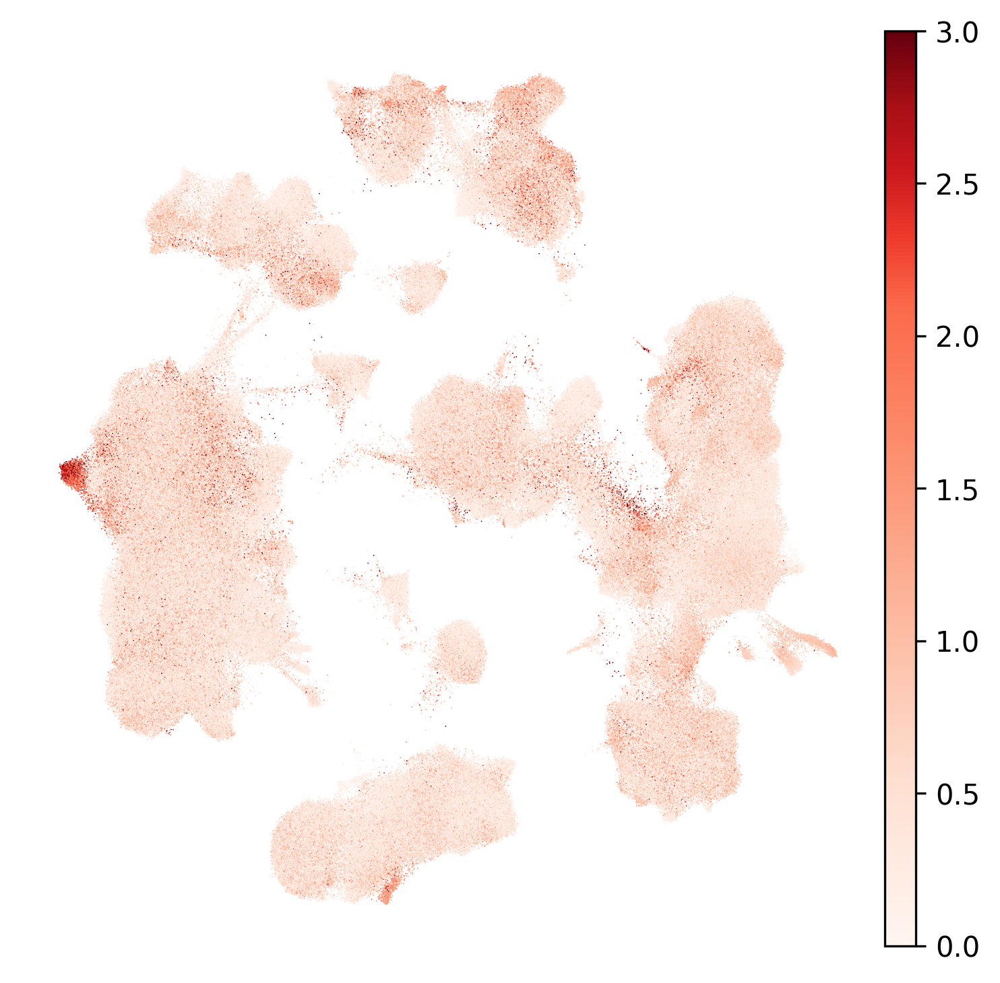

In [22]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="diff_denovo_ref", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/IPF_control_denovo_recalc_denovo_ref.png")

### 1.2 Compare with Control Group (scArches labeled)

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'condition_cat' as categorical


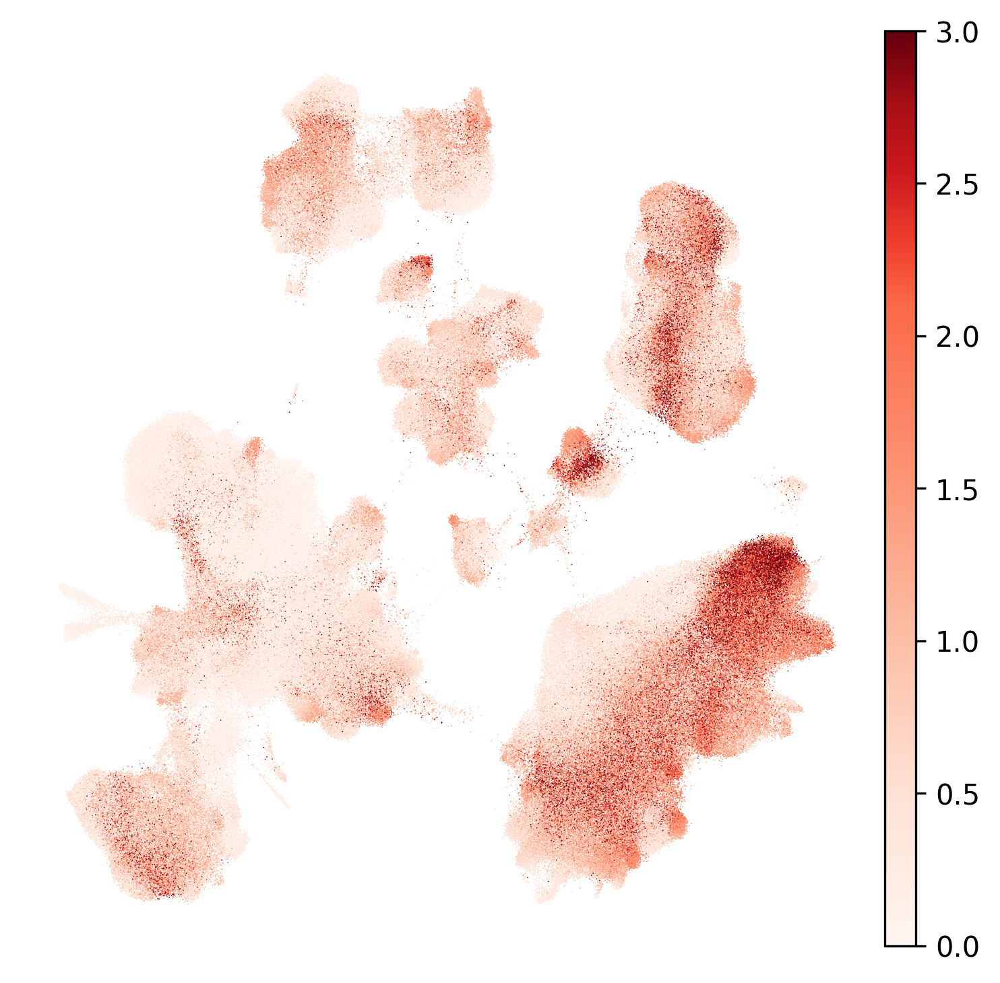

In [23]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="diff_scArches_labeled", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/IPF_control_scarches_unlabeled_scarches_labeled.png")

# Violin Plots 

In [20]:
# Sort labels by median of difference of logFC value
labels_sorted = list(scarches_unlabeled.obs.groupby("scanvi_label_original")["diff_denovo_recalc"].median().sort_values().index)

In [21]:
sort_by = [labels_sorted.index(x) for x in sorted(labels_sorted)]

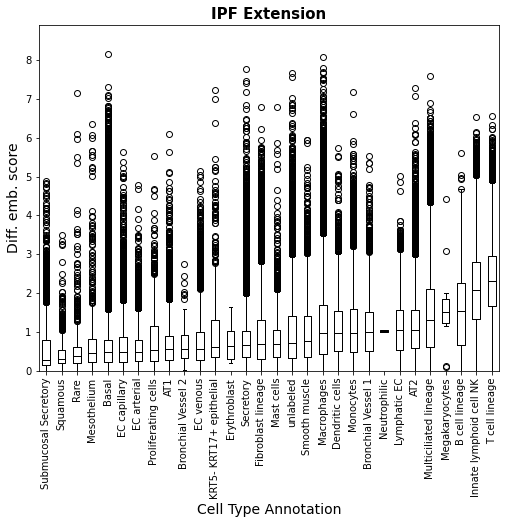

In [22]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc',by='scanvi_label_original', positions=sort_by,
                              boxprops=dict(color="0"), medianprops=dict(color="0"), whiskerprops=dict(color="0"))
plt.xticks(rotation=90)
plt.title("IPF Extension",fontweight="bold",size=15)
plt.xlabel("Cell Type Annotation",size=14)
plt.ylabel("Diff. emb. score",size=14)
plt.ylim(0,8.9)
plt.grid(False)
plt.suptitle('')
plt.subplots_adjust(bottom=0.3)
plt.savefig(f"figures/ipf_boxplot_scanvi_label_{date}.jpg",dpi=300)

In [68]:
cell_labels_lvl3 = ["Erythroblast", "KRT5- KRT17+ epithelial"]
cell_labels_lvl4 = ["Fibroblasts PLIN2+", "Ionocyte", "Neuroendocrine", "Langerin+ DC", "Regulatory T cells", "T cells proliferating"]

cells_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(cell_labels_lvl3)]
cells_lvl3.obs["diff_denovo_recalc_abs"] = abs(cells_lvl3.obs.diff_denovo_recalc)

cells_lvl4 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_4"].isin(cell_labels_lvl4)]
cells_lvl4.obs["diff_denovo_recalc_abs"] = abs(cells_lvl4.obs.diff_denovo_recalc)

Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.


In [69]:
labels_sorted_lvl3 = list(cells_lvl3.obs.groupby("ann_level_3")["diff_denovo_recalc_abs"].median().sort_values().index)
labels_sorted_lvl4 = list(cells_lvl4.obs.groupby("ann_level_4")["diff_denovo_recalc_abs"].median().sort_values().index)

In [70]:
sort_by_lvl3 = [labels_sorted_lvl3.index(x) for x in sorted(labels_sorted_lvl3)]
sort_by_lvl4 = [labels_sorted_lvl4.index(x) for x in sorted(labels_sorted_lvl4)]

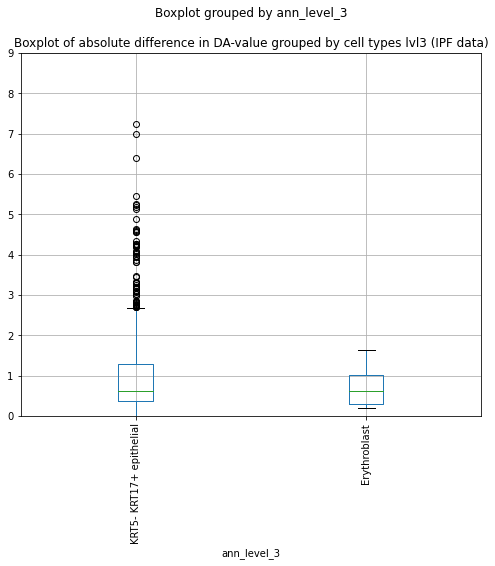

In [71]:
cells_lvl3.obs.boxplot(column='diff_denovo_recalc',by='ann_level_3', positions=sort_by_lvl3)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by cell types lvl3 (IPF data)")
plt.ylim(0,9)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/ipf_boxplot_new_lvl3_{date}.jpg")

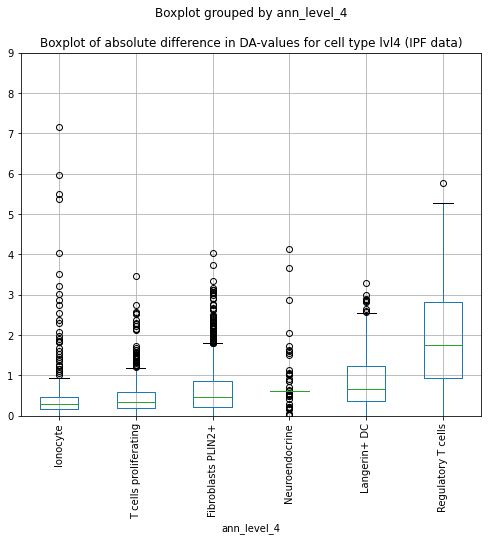

In [72]:
cells_lvl4.obs.boxplot(column='diff_denovo_recalc',by='ann_level_4', positions=sort_by_lvl4)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for cell type lvl4 (IPF data)")
plt.ylim(0,9)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/ipf_boxplot_lvl4_{date}.jpg")

# Clustering analysis

In [53]:
sc.tl.leiden(scarches_unlabeled, resolution= 0.1)

running Leiden clustering
    finished: found 11 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:31:46)


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'condition_cat' as categorical


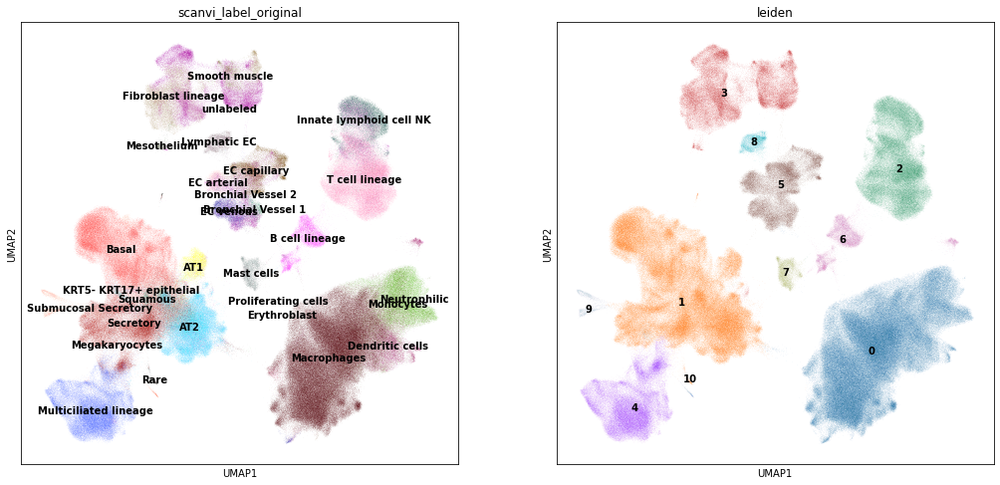

In [54]:
sc.pl.umap(scarches_unlabeled, color=["scanvi_label_original","leiden"], legend_loc="on data")

### Investigate NK and T Cell Subcluster

In [18]:
subset_nk_t = scarches_unlabeled[(scarches_unlabeled.obs.leiden == "2")].copy()

In [19]:
sc.pp.neighbors(subset_nk_t, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors


2022-02-08 13:54:09.562468: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-02-08 13:54:09.562498: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:23)


In [20]:
sc.tl.umap(subset_nk_t)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:02:08)


In [21]:
sc.tl.leiden(subset_nk_t, resolution= 0.1,key_added = "leiden_sub")

running Leiden clustering
    finished: found 2 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:00:46)


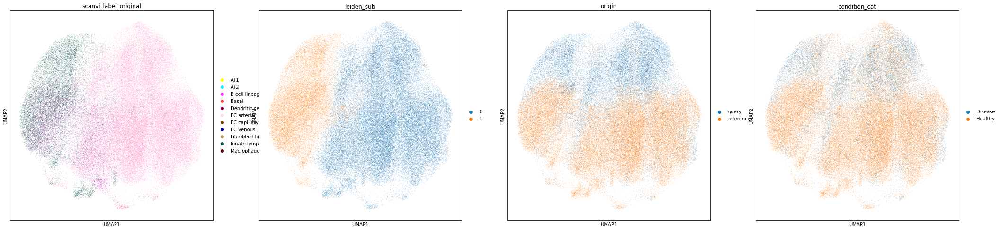

In [22]:
sc.pl.umap(subset_nk_t, color=["scanvi_label_original","leiden_sub", "origin","condition_cat"])

In [23]:
subset_nk = subset_nk_t[(subset_nk_t.obs.leiden_sub == "1")].copy()
subset_t = subset_nk_t[(subset_nk_t.obs.leiden_sub == "0")].copy()

In [24]:
sc.pp.neighbors(subset_nk, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(subset_nk)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:12)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:22)


In [25]:
sc.tl.leiden(subset_nk, resolution= 0.12, key_added="leiden_nk")

running Leiden clustering
    finished: found 3 clusters and added
    'leiden_nk', the cluster labels (adata.obs, categorical) (0:00:11)


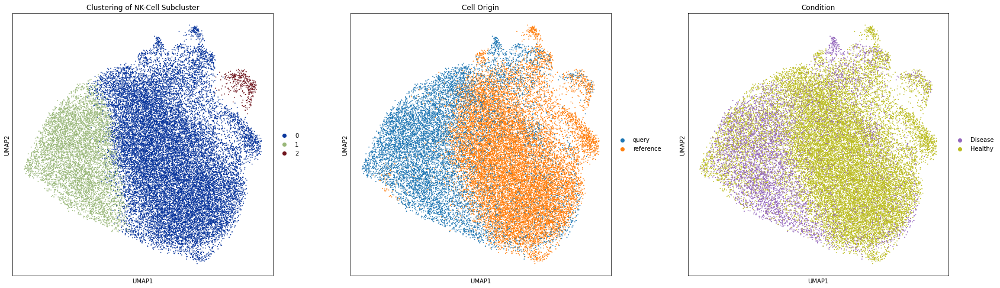

In [80]:
sc.pl.umap(subset_nk, color=["leiden_nk", "origin","condition_cat"], wspace=0.18, size = 12,
          title = ["Clustering of NK-Cell Subcluster", "Cell Origin", "Condition"],legend_fontsize ="medium"
           , palette=colordict
           , save="_clustering_nk_subcluster_origin_condition.pdf"
          )

In [27]:
sc.pp.neighbors(subset_t, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(subset_t)

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:31)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:01:20)


In [78]:
sc.tl.leiden(subset_t, resolution= 0.115, key_added="leiden_t")

running Leiden clustering
    finished: found 2 clusters and added
    'leiden_t', the cluster labels (adata.obs, categorical) (0:00:49)


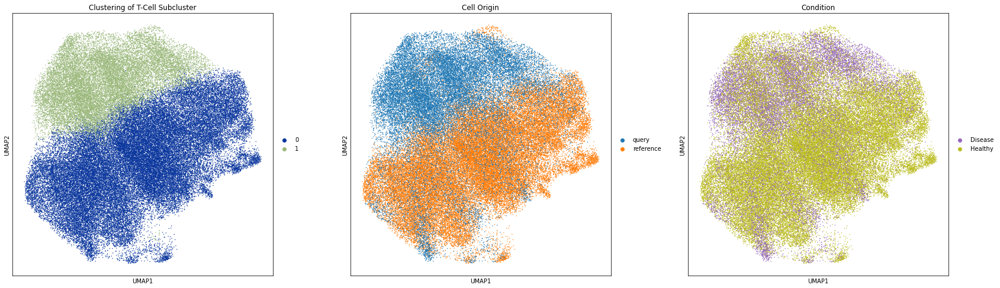

In [85]:
sc.pl.umap(subset_t, color=["leiden_t", "origin","condition_cat"], wspace=0.18, size = 8,
          title = ["Clustering of T-Cell Subcluster", "Cell Origin", "Condition"],legend_fontsize ="medium"
           , palette=colordict
           , save="_clustering_t_subcluster_origin_condition.pdf"
          )

Switch from ensembl IDs to gene names, as it's easier to interpret.

Get original data with raw counts for all genes for differential expression testing

Normalize raw counts for DE testing.

In [67]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/IPF_labeled_normalized.h5ad")

In [68]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v5.h5ad")

In [69]:
source_adata.var = source_adata.var.set_index("gene_ids")

In [70]:
combined_data = source_adata.concatenate(query_data, join="outer")

In [71]:
combined_data.X = np.nan_to_num(combined_data.X, copy=False)

In [72]:
combined_data.X = combined_data.layers["counts"].copy()

In [92]:
#Get leiden cluster assignment for nk cells
combined_data.obs["leiden_nk_scarches"] = pd.merge(combined_data.obs,subset_nk.obs.leiden_nk, how="left", left_index=True, right_index=True).leiden_nk

In [93]:
combined_data.obs["leiden_t_scarches"] = pd.merge(combined_data.obs,subset_t.obs.leiden_t, how="left", left_index=True, right_index=True).leiden_t

In [73]:
combined_data.var_names.name = "index"
combined_data.obs["age"] = combined_data.obs["age"].astype(str)
combined_data.var["highly_variable-0"] = combined_data.var["highly_variable-0"].astype(str)
combined_data.var["highly_variable_intersection-0"] = combined_data.var["highly_variable_intersection-0"].astype(str)

In [101]:
combined_data.write("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/original_count_data.h5ad")
# .X: raw counts for all genes
# .layers["counts"]: raw counts for all genes

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'age' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'highly_variable-0' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a n

In [ ]:
combined_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/original_count_data.h5ad")

In [102]:
combined_data_nk = combined_data[~pd.isna(combined_data.obs.leiden_nk_scarches)]
combined_data_t = combined_data[~pd.isna(combined_data.obs.leiden_t_scarches)]

In [ ]:
# normalize 
combined_data_nk_norm = scib_excerpts.SCRAN_normalize(combined_data_nk, log_transform=False)

In [105]:
# normalize 
combined_data_t_norm = scib_excerpts.SCRAN_normalize(combined_data_t, log_transform=False)

normalizing by total count per cell
    finished (0:00:03): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
computing PCA
    with n_comps=50
    finished (0:00:42)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:08)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 22 clusters and added
    'groups', the cluster labels (adata.obs, categorical) (0:00:16)


R[write to console]: dimnames(.) <- NULL:  translated to 
dimnames(.) <- list(NULL,NULL)  <==>  unname(.)



In [107]:
combined_data_nk_norm.var.index = combined_data_nk_norm.var["symbol-0-0-0-0-0-0-1"]
combined_data_t_norm.var.index = combined_data_t_norm.var["symbol-0-0-0-0-0-0-1"]

In [108]:
combined_data_nk_norm_u = combined_data_nk_norm[:, ~combined_data_nk_norm.var.index.duplicated(keep ='first')]
combined_data_t_norm_u = combined_data_t_norm[:, ~combined_data_t_norm.var.index.duplicated(keep ='first')]

In [109]:
combined_data_nk_norm_u.obs = pd.merge(combined_data_nk_norm_u.obs,subset_nk.obs[["scanvi_label_original","origin", 'logFC_avg', 'logFC_avg_disease_healthy', 'condition_cat', 'diff_denovo_recalc', 'diff_denovo_ref', 'diff_scArches_labeled', 'diff_denovo_recalc_disease_healthy', 'leiden_sub', 'leiden_nk']], how="left", left_index=True, right_index=True)
combined_data_t_norm_u.obs = pd.merge(combined_data_t_norm_u.obs,subset_t.obs[["scanvi_label_original","origin", 'logFC_avg', 'logFC_avg_disease_healthy', 'condition_cat', 'diff_denovo_recalc', 'diff_denovo_ref', 'diff_scArches_labeled', 'diff_denovo_recalc_disease_healthy', 'leiden_sub', 'leiden_t']], how="left", left_index=True, right_index=True)

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [110]:
combined_data_nk_norm_u.obsm["X_scArches"] = subset_nk.obsm["X_scArches"]
combined_data_t_norm_u.obsm["X_scArches"] = subset_t.obsm["X_scArches"]

In [111]:
combined_data_nk_norm_u.var_names.name = "index"
combined_data_t_norm_u.var_names.name = "index"

In [112]:
combined_data_nk_norm_u.write("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/original_count_data_norm_nk_u.h5ad")
combined_data_t_norm_u.write("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/original_count_data_norm_t_u.h5ad")

In [4]:
combined_data_nk_norm_u = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/original_count_data_norm_nk_u.h5ad")
combined_data_t_norm_u = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Clustering/original_count_data_norm_t_u.h5ad")

### DE Analysis: NK-Cell Subcluster

In [5]:
sc.pp.neighbors(combined_data_nk_norm_u, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(combined_data_nk_norm_u)
sc.tl.leiden(combined_data_nk_norm_u, resolution= 0.12, key_added="leiden_nk")

computing neighbors


2022-03-07 17:47:12.337833: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-03-07 17:47:12.337863: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:25)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:21)
running Leiden clustering
    finished: found 3 clusters and added
    'leiden_nk', the cluster labels (adata.obs, categorical) (0:00:10)


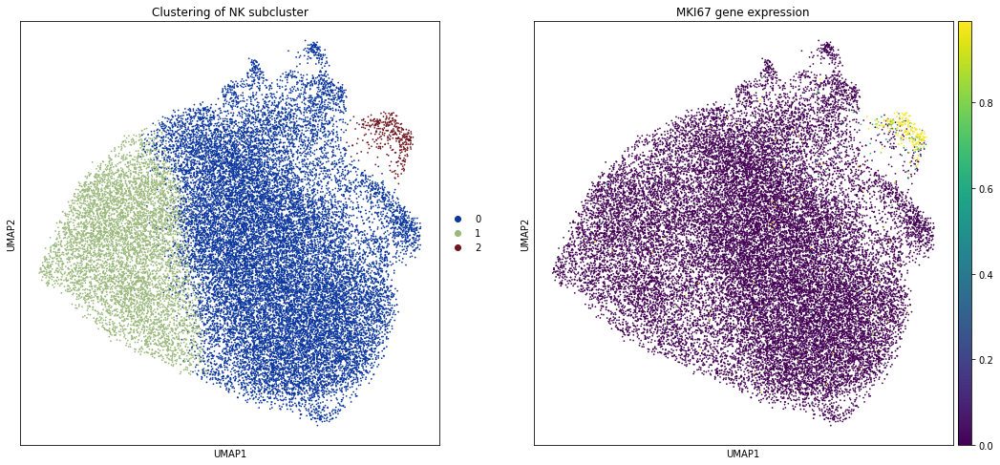

In [27]:
sc.pl.umap(combined_data_nk_norm_u, color=["leiden_nk", "MKI67"],size=12, vmax=0.99,
          title = ["Clustering of NK subcluster", "MKI67 gene expression"],  palette=colordict
          #,save = "figure_clustering_nk_subcluster_mki67.pdf"
          )

In [7]:
nk_subcluster_compare = combined_data_nk_norm_u[combined_data_nk_norm_u.obs.leiden_nk!="2"]

ranking genes


Trying to set attribute `._uns` of view, copying.


    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)


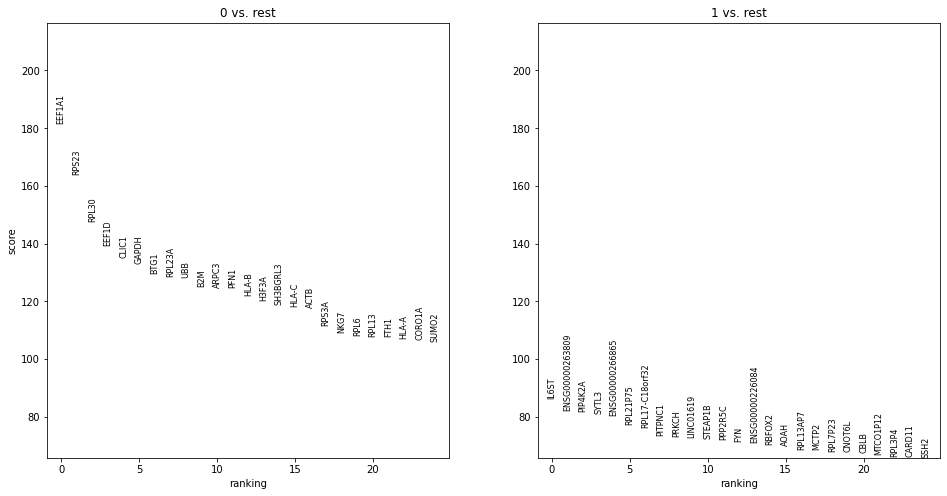

In [8]:
sc.tl.rank_genes_groups(nk_subcluster_compare, groupby='leiden_nk_scarches', method='t-test', key_added = "t-test", use_raw=False)
sc.pl.rank_genes_groups(nk_subcluster_compare, n_genes=25, key = "t-test", use_raw = False)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 2, max_out_group_fraction: 0.5


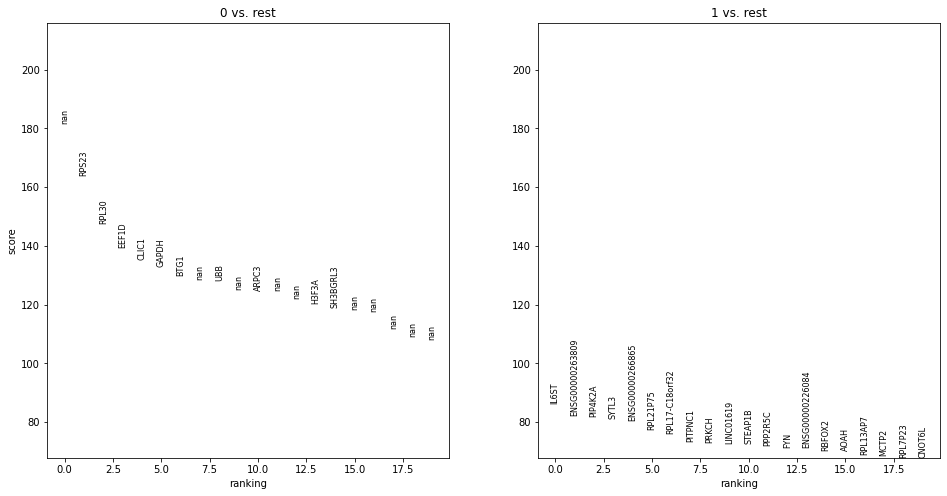

In [9]:
sc.tl.filter_rank_genes_groups(nk_subcluster_compare, min_fold_change=2, key="t-test", use_raw=False)
# visualize results
sc.pl.rank_genes_groups(nk_subcluster_compare, key='rank_genes_groups_filtered', use_raw = False)

In [10]:
table_de_nk = sc.get.rank_genes_groups_df(nk_subcluster_compare, key='rank_genes_groups_filtered', group = None)

In [11]:
table_de_nk = table_de_nk[~pd.isna(table_de_nk.names)]

In [12]:
nk_subcluster_compare_plot = sc.pp.subsample(nk_subcluster_compare,fraction=1.,copy=True)

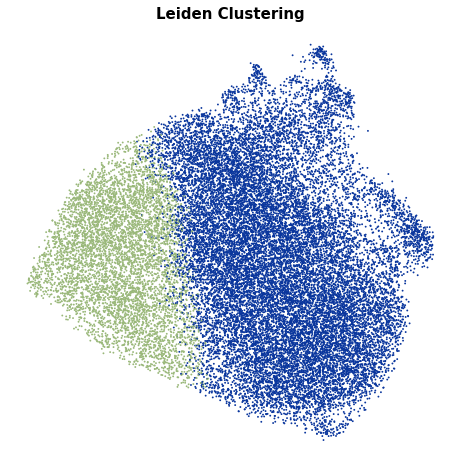

In [15]:
ax = sc.pl.umap(nk_subcluster_compare_plot, color=["leiden_nk_scarches"],size=14, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False,legend_loc=False,
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Leiden Clustering", fontweight="bold",fontsize=15)
#plt.show()
plt.savefig("figures/ipf_nk_cells_de_leiden.png")

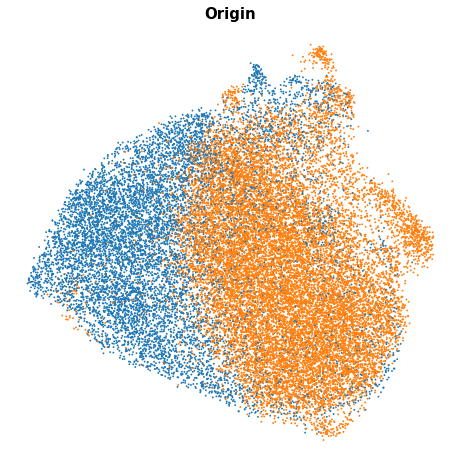

In [16]:
ax = sc.pl.umap(nk_subcluster_compare_plot, color=["origin"],size=14, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False,legend_loc=False
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Origin", fontweight="bold",fontsize=15)
#plt.show()
plt.savefig("figures/ipf_nk_cells_de_origin.png")

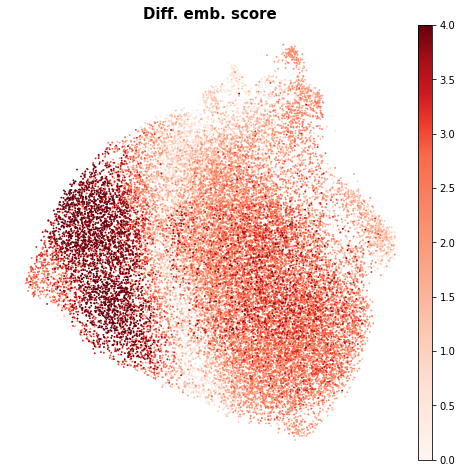

In [17]:
ax = sc.pl.umap(nk_subcluster_compare_plot, color=["diff_denovo_recalc"],size=14, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Diff. emb. score", fontweight="bold",fontsize=15)
#plt.show()
plt.savefig("figures/ipf_nk_cells_de_diff_emb_score.png")

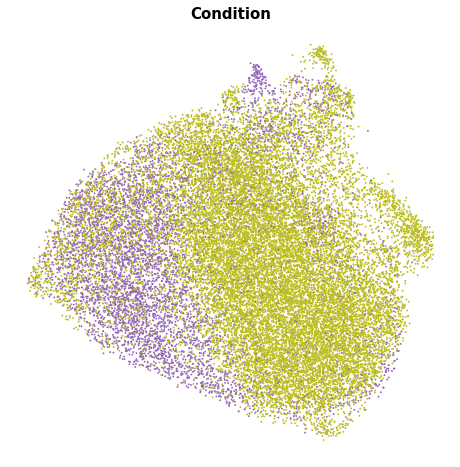

In [18]:
ax = sc.pl.umap(nk_subcluster_compare_plot, color=["condition_cat"],size=14, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False,legend_loc=False,
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Condition", fontweight="bold",fontsize=15)
#plt.show()
plt.savefig("figures/ipf_nk_cells_de_condition.png")

In [20]:
de_genes = table_de_nk[table_de_nk.group=="1"].names.tolist()
de_genes = [x for x in de_genes if not x.startswith("ENSG")][0:20]


In [21]:
conditions =[
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches!="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches!="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease")
]
choices = ["High Diff. emb. score & IPF","High Diff. emb. score & Healthy","Low Diff. emb. score & IPF","Low Diff. emb. score & Healthy"]

In [19]:
conditions_II =[
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease") & ~(nk_subcluster_compare_plot.obs.dataset.isin(["Kaminski_2020","Sheppard_2020","Banovich_Kropski_2020_disease","Banovich_Kropski_2020"])),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Kaminski_2020"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Sheppard_2020"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Banovich_Kropski_2020_disease"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Banovich_Kropski_2020"),
    
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease") & ~(nk_subcluster_compare_plot.obs.dataset.isin(["Kaminski_2020","Sheppard_2020","Banovich_Kropski_2020_disease","Banovich_Kropski_2020"])),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Kaminski_2020"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Sheppard_2020"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Banovich_Kropski_2020_disease"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches=="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease")  & (nk_subcluster_compare_plot.obs.dataset=="Banovich_Kropski_2020"),
    
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches!="1") & (nk_subcluster_compare_plot.obs.condition_cat=="Disease"),
    (nk_subcluster_compare_plot.obs.leiden_nk_scarches!="1") & (nk_subcluster_compare_plot.obs.condition_cat!="Disease")
]
choices_II = ["High Diff. emb. score & IPF (others)",
              "High Diff. emb. score & IPF (Kaminski_2020)",
              "High Diff. emb. score & IPF (Sheppard_2020)",
              "High Diff. emb. score & IPF (Banovich_Kropski_2020_disease)",
              "High Diff. emb. score & IPF (Banovich_Kropski_2020)",
              
              "High Diff. emb. score & Healthy (others)",
              "High Diff. emb. score & Healthy (Kaminski_2020)",
              "High Diff. emb. score & Healthy (Sheppard_2020)",
              "High Diff. emb. score & Healthy (Banovich_Kropski_2020_disease)",
              "High Diff. emb. score & Healthy (Banovich_Kropski_2020)",
              
              "Low Diff. emb. score & IPF",
              "Low Diff. emb. score & Healthy"]

In [22]:
nk_subcluster_compare_plot.obs["plot_group_de"] = np.select(conditions,choices,default="other")
nk_subcluster_compare_plot.obs["plot_group_de_II"] = np.select(conditions_II,choices_II,default="other")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'plot_group_de' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'plot_group_de_II' as categorical


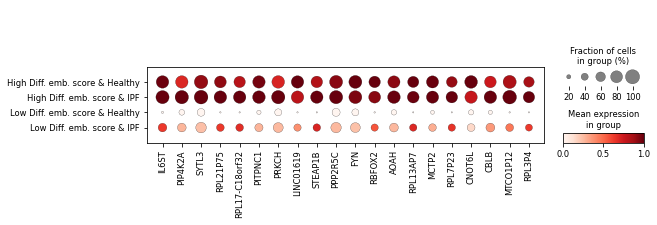

In [23]:
sc.pl.dotplot(nk_subcluster_compare_plot, de_genes, groupby='plot_group_de',standard_scale='var',
             save="ipf_nk_cells_de_analysis_split_I.png")

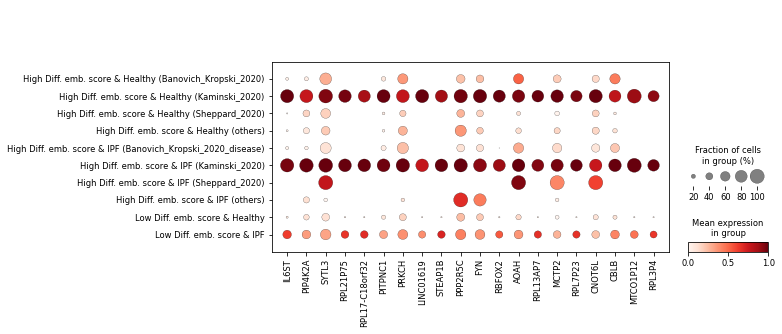

In [24]:
sc.pl.dotplot(nk_subcluster_compare_plot, de_genes, groupby='plot_group_de_II',standard_scale='var',
             save="ipf_nk_cells_de_analysis_split.png")

In [17]:
pd.concat([table_de_nk[table_de_nk.group=="0"].head(100), table_de_nk[table_de_nk.group=="1"].head(100)]).to_csv("/storage/groups/ml01/workspace/jan.domke/Data/ipf_nk_de_genes.csv")

### DE Analysis: T-Cell Subcluster

In [20]:
sc.pp.neighbors(combined_data_t_norm_u, n_neighbors=50, n_pcs=30, use_rep="X_scArches")
sc.tl.umap(combined_data_t_norm_u)
sc.tl.leiden(combined_data_t_norm_u, resolution= 0.115, key_added="leiden_t")

computing neighbors


2022-03-04 08:12:12.008295: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-03-04 08:12:12.008361: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:47)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:01:21)
running Leiden clustering
    finished: found 2 clusters and added
    'leiden_t', the cluster labels (adata.obs, categorical) (0:00:45)


In [21]:
combined_data_t_norm_u_plot = sc.pp.subsample(combined_data_t_norm_u,fraction=1.,copy=True)

Text(0.5, 1.0, 'Leiden Clustering')

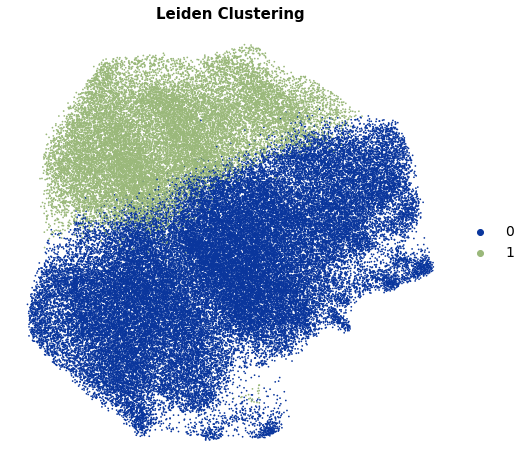

In [53]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color=["leiden_t"],size=12, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False,
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Leiden Clustering", fontweight="bold",fontsize=15)
#plt.show()
#plt.savefig("figures/ipf_t_cells_de_leiden.png")

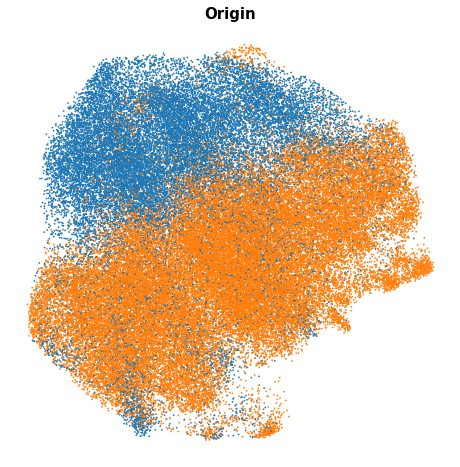

In [50]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color=["origin"],size=12, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False,legend_loc=False
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Origin", fontweight="bold",fontsize=15)
#plt.show()
plt.savefig("figures/ipf_t_cells_de_origin.png")

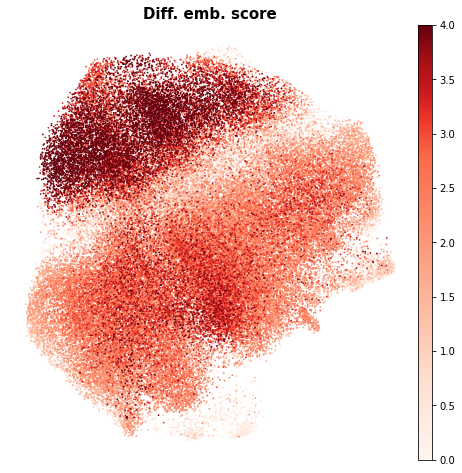

In [45]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color=["diff_denovo_recalc"],size=12, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Diff. emb. score", fontweight="bold",fontsize=15)
#plt.show()
plt.savefig("figures/ipf_t_cells_de_diff_emb_score.png")

Text(0.5, 1.0, 'Condition')

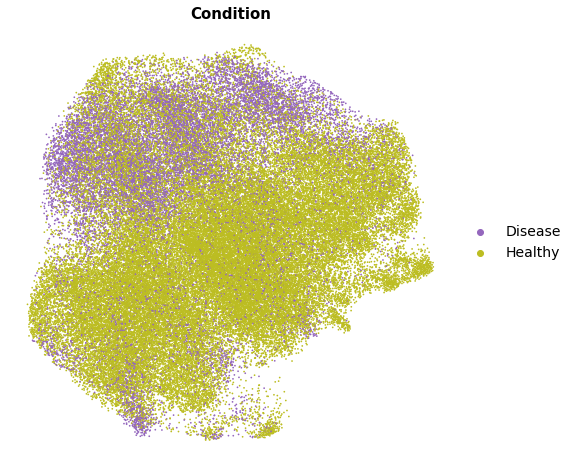

In [52]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color=["condition_cat"],size=12, vmax=4,vmin=0,cmap=new_reds, legend_fontsize=14,
          title = "",  palette=colordict,hspace=0.1,frameon=False,show=False
          #,save = "_ipf_t_cells_split_basis.png"
          )
fig = ax.get_figure()
plt.title("Condition", fontweight="bold",fontsize=15)
#plt.show()
#plt.savefig("figures/ipf_t_cells_de_condition.png")

ranking genes
    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:02)


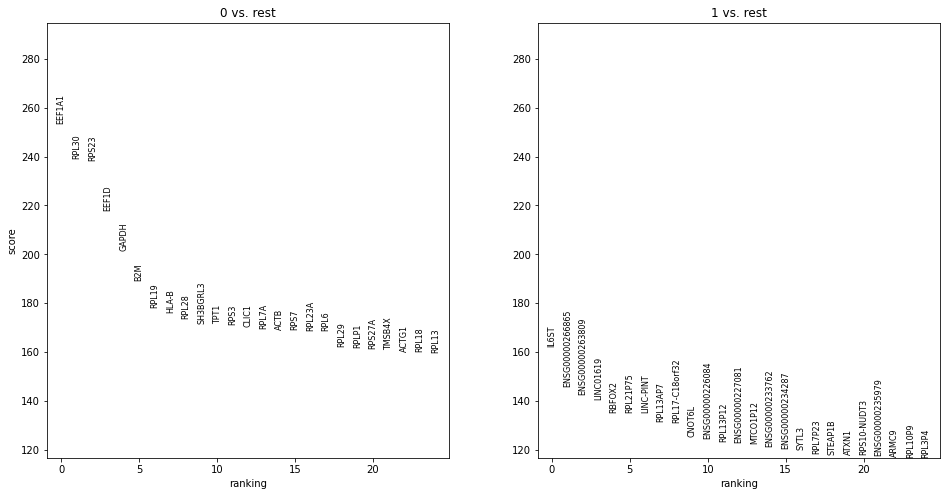

In [22]:
sc.tl.rank_genes_groups(combined_data_t_norm_u, groupby='leiden_t_scarches', method='t-test', key_added = "t-test", use_raw=False)
sc.pl.rank_genes_groups(combined_data_t_norm_u, n_genes=25, key = "t-test", use_raw = False)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 2, max_out_group_fraction: 0.5


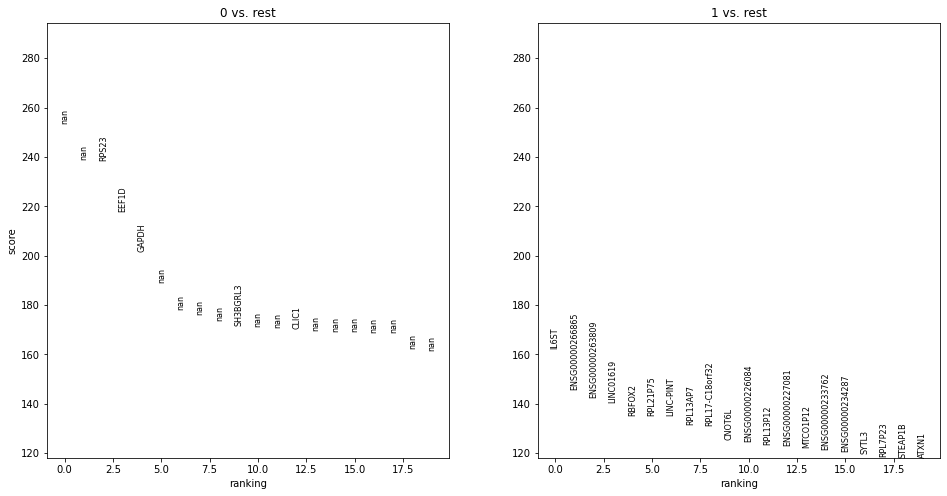

In [23]:
sc.tl.filter_rank_genes_groups(combined_data_t_norm_u, min_fold_change=2, key="t-test", use_raw=False)
# visualize results
sc.pl.rank_genes_groups(combined_data_t_norm_u, key='rank_genes_groups_filtered', use_raw = False)

In [26]:
table_de_t = sc.get.rank_genes_groups_df(combined_data_t_norm_u, key='rank_genes_groups_filtered', group = None)

In [27]:
table_de_t = table_de_t[~pd.isna(table_de_t.names)]

In [37]:
pd.concat([table_de_t[table_de_t.group=="0"].head(100), table_de_t[table_de_t.group=="1"].head(100)]).to_csv("/storage/groups/ml01/workspace/jan.domke/Data/top_100_de_genes_per_group_t_cells.csv")

try unfiltered version for GSEA

In [35]:
table_de_unfiltered = sc.get.rank_genes_groups_df(combined_data_t_norm_u, key='t-test', group = None)

In [36]:
table_de_unfiltered = table_de_unfiltered[~pd.isna(table_de_unfiltered.names)]

### Dotplot 4 groups (high-milo ipf, high-milo healthy, low-milo ipf, low-milo healthy)

In [66]:
de_genes = table_de_t[table_de_t.group=="1"].names.tolist()
de_genes = [x for x in de_genes if not x.startswith("ENSG")][0:20]


In [67]:
conditions =[
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease"),
    (combined_data_t_norm_u.obs.leiden_t_scarches!="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease"),
    (combined_data_t_norm_u.obs.leiden_t_scarches!="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease")
]
choices = ["High Diff. emb. score & IPF","High Diff. emb. score & Healthy","Low Diff. emb. score & IPF","Low Diff. emb. score & Healthy"]

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


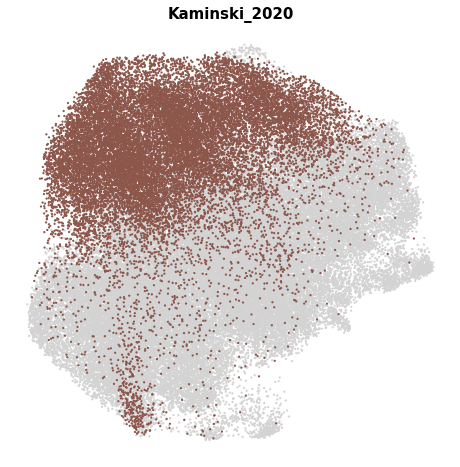

In [56]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color="dataset", size=20,frameon=False, legend_loc=False,
           groups=["Kaminski_2020"],show=False)
fig = ax.get_figure()
plt.title("Kaminski_2020", fontsize=15, fontweight="bold")
plt.savefig("figures/ipf_t_cells_de_kaminski.png")

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


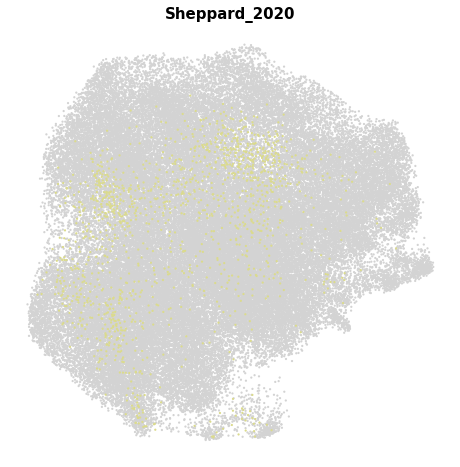

In [57]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color="dataset", size=20,frameon=False, legend_loc=False,
           groups=["Sheppard_2020"],show=False)
fig = ax.get_figure()
plt.title("Sheppard_2020", fontsize=15, fontweight="bold")
plt.savefig("figures/ipf_t_cells_de_sheppard.png")

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


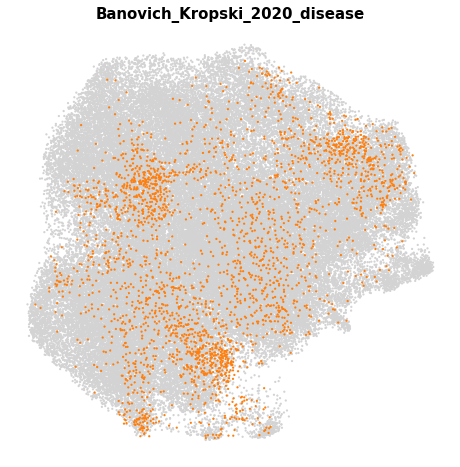

In [59]:
ax = sc.pl.umap(combined_data_t_norm_u_plot, color="dataset", size=20,frameon=False, legend_loc=False,
           groups=["Banovich_Kropski_2020_disease"],show=False)
fig = ax.get_figure()
plt.title("Banovich_Kropski_2020_disease", fontsize=15, fontweight="bold")
plt.savefig("figures/ipf_t_cells_de_banovich_disease.png")

In [69]:
conditions_II =[
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease") & ~(combined_data_t_norm_u.obs.dataset.isin(["Kaminski_2020","Sheppard_2020","Banovich_Kropski_2020_disease","Banovich_Kropski_2020"])),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease")  & (combined_data_t_norm_u.obs.dataset=="Kaminski_2020"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease")  & (combined_data_t_norm_u.obs.dataset=="Sheppard_2020"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease")  & (combined_data_t_norm_u.obs.dataset=="Banovich_Kropski_2020_disease"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease")  & (combined_data_t_norm_u.obs.dataset=="Banovich_Kropski_2020"),
    
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease") & ~(combined_data_t_norm_u.obs.dataset.isin(["Kaminski_2020","Sheppard_2020","Banovich_Kropski_2020_disease","Banovich_Kropski_2020"])),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease")  & (combined_data_t_norm_u.obs.dataset=="Kaminski_2020"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease")  & (combined_data_t_norm_u.obs.dataset=="Sheppard_2020"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease")  & (combined_data_t_norm_u.obs.dataset=="Banovich_Kropski_2020_disease"),
    (combined_data_t_norm_u.obs.leiden_t_scarches=="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease")  & (combined_data_t_norm_u.obs.dataset=="Banovich_Kropski_2020"),
    
    (combined_data_t_norm_u.obs.leiden_t_scarches!="1") & (combined_data_t_norm_u.obs.condition_cat=="Disease"),
    (combined_data_t_norm_u.obs.leiden_t_scarches!="1") & (combined_data_t_norm_u.obs.condition_cat!="Disease")
]
choices_II = ["High Diff. emb. score & IPF (others)",
              "High Diff. emb. score & IPF (Kaminski_2020)",
              "High Diff. emb. score & IPF (Sheppard_2020)",
              "High Diff. emb. score & IPF (Banovich_Kropski_2020_disease)",
              "High Diff. emb. score & IPF (Banovich_Kropski_2020)",
              
              "High Diff. emb. score & Healthy (others)",
              "High Diff. emb. score & Healthy (Kaminski_2020)",
              "High Diff. emb. score & Healthy (Sheppard_2020)",
              "High Diff. emb. score & Healthy (Banovich_Kropski_2020_disease)",
              "High Diff. emb. score & Healthy (Banovich_Kropski_2020)",
              
              "Low Diff. emb. score & IPF",
              "Low Diff. emb. score & Healthy"]

In [70]:
combined_data_t_norm_u.obs["plot_group_de"] = np.select(conditions,choices,default="other")
combined_data_t_norm_u.obs["plot_group_de_II"] = np.select(conditions_II,choices_II,default="other")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'plot_group_de' as categorical
/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'plot_group_de_II' as categorical


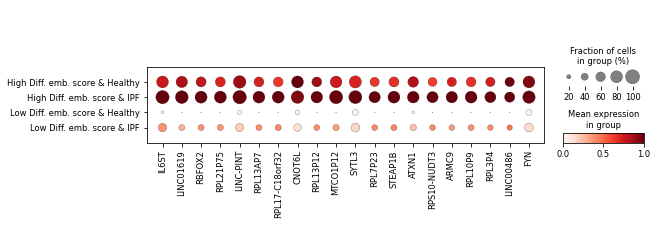

In [71]:
sc.pl.dotplot(combined_data_t_norm_u, de_genes, groupby='plot_group_de',standard_scale='var',
             save="ipf_t_cells_de_analysis_split_I.png")

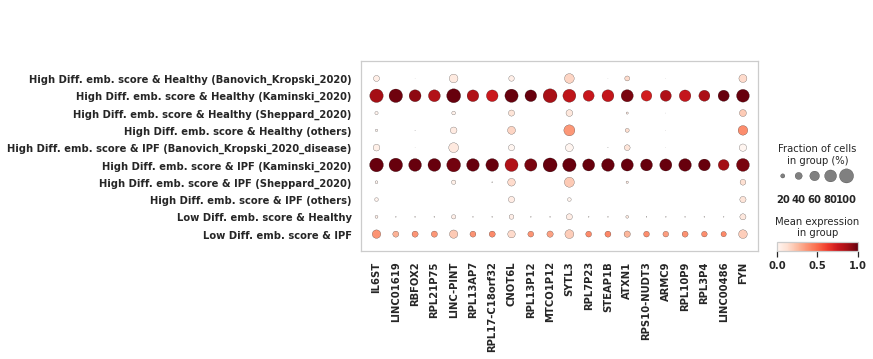

In [143]:
sc.pl.dotplot(combined_data_t_norm_u, de_genes, groupby='plot_group_de_II',standard_scale='var',
             save="ipf_t_cells_de_analysis_split.png")

## Gene Set Enrichment Analysis (GSEA)

In [28]:
background_genes = combined_data_t_norm_u.var["ensembl-0-0-0-0-0-0-1"].astype(str).tolist()

### 1. GSEA T-Cells

In [30]:
genes_up = table_de_t[table_de_t.group=="1"].names.tolist()
genes_down = table_de_t[table_de_t.group=="0"].names.tolist()

In [31]:
genes_up_no_code = [x for x in genes_up if x.startswith("ENSG")]
genes_up_code = [x for x in genes_up if x not in genes_up_no_code][0:1000]
genes_down_no_code = [x for x in genes_down if x.startswith("ENSG")]
genes_down_code = [x for x in genes_down if x not in genes_down_no_code][0:1000]

In [33]:
gp = GProfiler(return_dataframe=True, user_agent="g:GOSt")
enrichment_up = gp.profile(
    query=genes_up_code,
    organism="hsapiens",
    ordered=True,
    sources=["GO:BP"],  # , "GO:CC", "REAC", "CORUM", "HPO"],
    user_threshold=0.05,
    all_results=True,
    significance_threshold_method="fdr",
    background=background_genes,
    domain_scope='custom_annotated',
    no_evidences=False,
)
enrichment_down = gp.profile(
    query=genes_down_code,
    organism="hsapiens",
    ordered=True,
    sources=["GO:BP"],  # , "GO:CC", "REAC", "CORUM", "HPO"],
    user_threshold=0.05,
    all_results=True,
    significance_threshold_method="fdr",
    background=background_genes,
    domain_scope='custom_annotated',
    no_evidences=False,
)

Number of significant terms: 775. We will only plot 20.


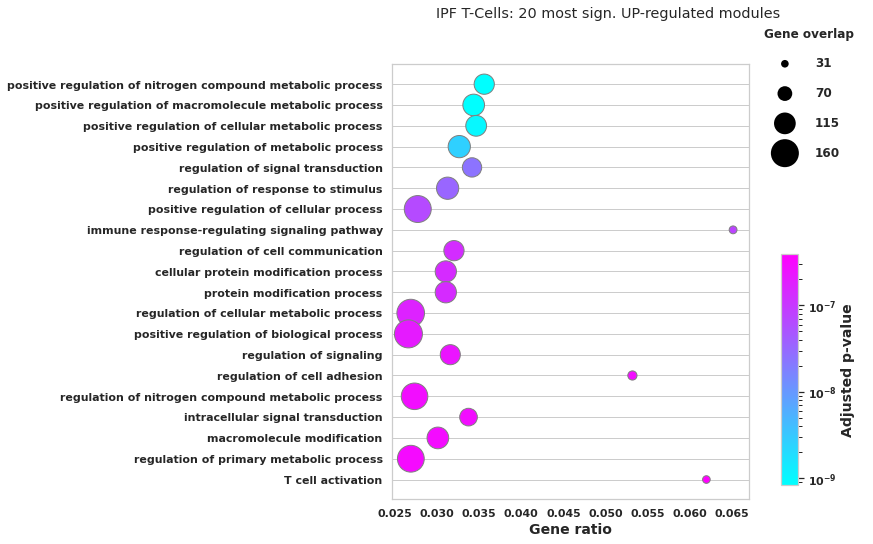

Of the total 
4655
terms, there are 
4655 different GO:BP groups 


In [39]:
enr_up = gprofiler_custom_LISA.gprofiler_enrich(
    genes_up_code,
    n_modules_to_plot=20,
    ordered=True,
    sources=["GO:BP"],  # , "REAC", "CORUM", "HPO"],
    title="IPF T-Cells: 20 most sign. UP-regulated modules",
)

Number of significant terms: 504. We will only plot 20.


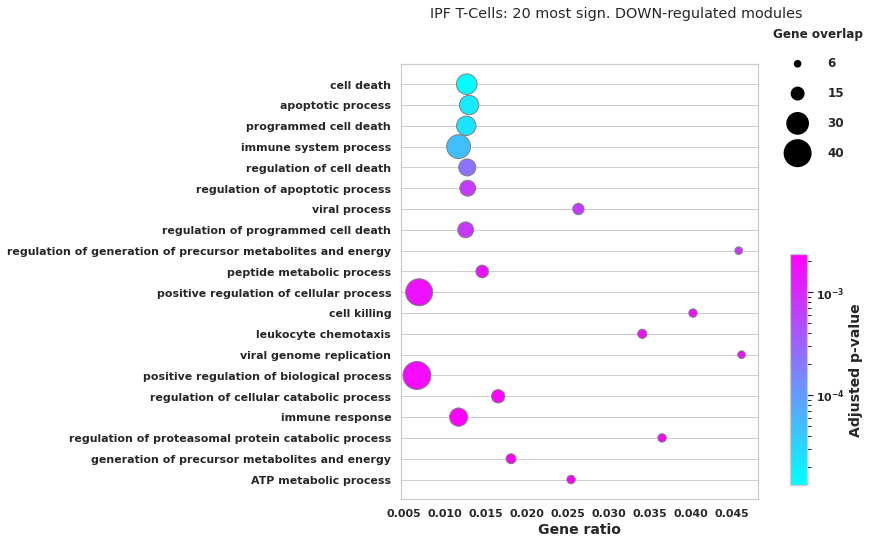

Of the total 
2320
terms, there are 
2320 different GO:BP groups 


In [40]:
enr_down = gprofiler_custom_LISA.gprofiler_enrich(
    genes_down_code,
    n_modules_to_plot=20,
    ordered=True,
    sources=["GO:BP"],
    title="IPF T-Cells: 20 most sign. DOWN-regulated modules",
)

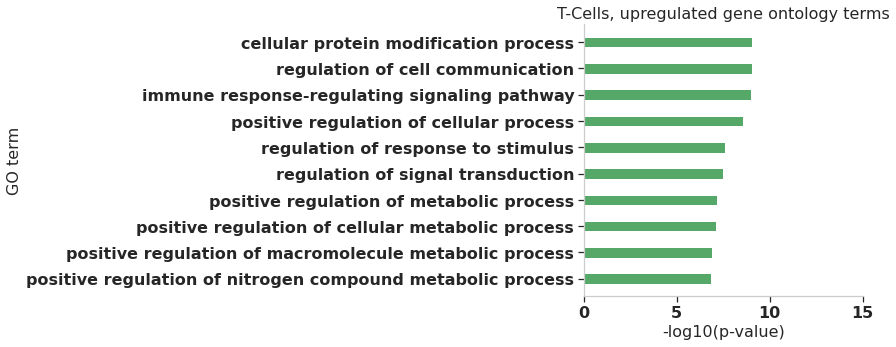

In [41]:
fz = 16
with plt.rc_context(
    {
        "figure.figsize": (5, 5),
        "xtick.labelsize": fz,
        "ytick.labelsize": fz,
        "legend.title_fontsize": "xx-large",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "xtick.bottom": True,
        "ytick.left": True,
    }
):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.barh(
        y=enr_up.name[:10],
        width=-np.log10(enr_up.p_value[:10][::-1]),
        height=0.4,
        color="g",
    )
    plt.xlabel("-log10(p-value)", fontsize=fz)
    plt.ylabel("GO term", fontsize=fz)
    plt.title(f"T-Cells, upregulated gene ontology terms", fontsize=fz)
    plt.xlim((0, 15))
    plt.grid(None)
    plt.show()

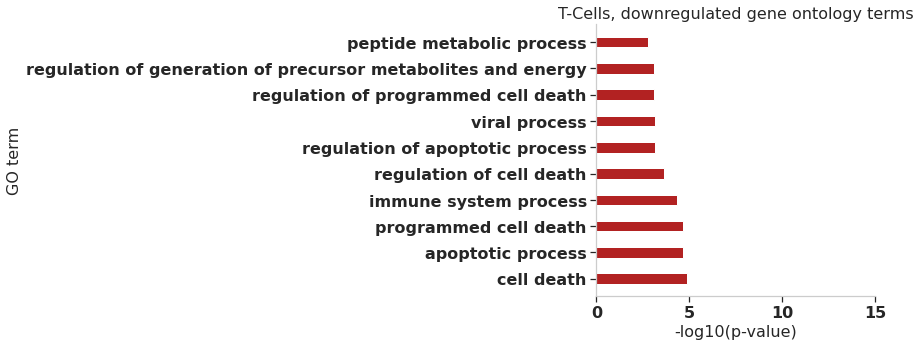

In [42]:
fz = 16
with plt.rc_context(
    {
        "figure.figsize": (5, 5),
        "xtick.labelsize": fz,
        "ytick.labelsize": fz,
        "legend.title_fontsize": "xx-large",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "xtick.bottom": True,
        "ytick.left": True,
    }
):
    y = enr_down.name[:10].copy()
    # shorten label:
    for row, val in enumerate(enr_down.name[:10]):
        if (
            val
            == "antigen processing and presentation of exogenous peptide antigen via MHC class I, TAP-dependent"
        ):
            y[
                row
            ] = "antigen processing and presentation of exogenous\npeptide antigen via MHC class I, TAP-dependent"
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.barh(
        y=y,
        width=-np.log10(enr_down.p_value[:10]),
        height=0.4,
        color="firebrick",
    )
    plt.xlabel("-log10(p-value)", fontsize=fz)
    plt.ylabel("GO term", fontsize=fz)
    plt.title(f"T-Cells, downregulated gene ontology terms", fontsize=fz)
    plt.xlim((0, 15))
    plt.grid(None)
    plt.show()

### 1. GSEA NK-Cells

In [33]:
genes_up_nk = table_de_nk[table_de_nk.group=="1"].names.tolist()
genes_down_nk = table_de_nk[table_de_nk.group=="0"].names.tolist()

In [34]:
genes_up_nk_no_code = [x for x in genes_up_nk if x.startswith("ENSG")]
genes_up_nk_code = [x for x in genes_up_nk if x not in genes_up_nk_no_code]
genes_down_nk_no_code = [x for x in genes_down_nk if x.startswith("ENSG")]
genes_down_nk_code = [x for x in genes_down_nk if x not in genes_down_nk_no_code]

In [37]:
gp = GProfiler(return_dataframe=True, user_agent="g:GOSt")
enrichment_up = gp.profile(
    query=genes_up_nk_code,
    organism="hsapiens",
    ordered=True,
    sources=["GO:BP"],  # , "GO:CC", "REAC", "CORUM", "HPO"],
    user_threshold=0.05,
    all_results=True,
    significance_threshold_method="fdr",
    background=background_genes,
    domain_scope='custom_annotated',
    no_evidences=False,
)
enrichment_down = gp.profile(
    query=genes_down_nk_code,
    organism="hsapiens",
    ordered=True,
    sources=["GO:BP"],  # , "GO:CC", "REAC", "CORUM", "HPO"],
    user_threshold=0.05,
    all_results=True,
    significance_threshold_method="fdr",
    background=background_genes,
    domain_scope='custom_annotated',
    no_evidences=False,
)

Number of significant terms: 1099. We will only plot 20.


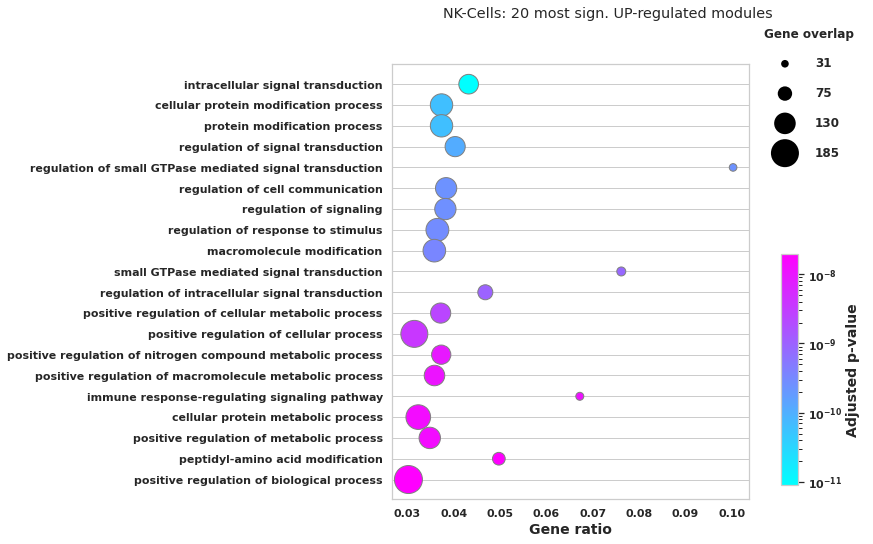

Of the total 
4854
terms, there are 
4854 different GO:BP groups 


In [38]:
enr_up = gprofiler_custom_LISA.gprofiler_enrich(
    genes_up_nk_code,
    n_modules_to_plot=20,
    ordered=True,
    sources=["GO:BP"],  # , "REAC", "CORUM", "HPO"],
    title="NK-Cells: 20 most sign. UP-regulated modules",
)

Number of significant terms: 950. We will only plot 20.


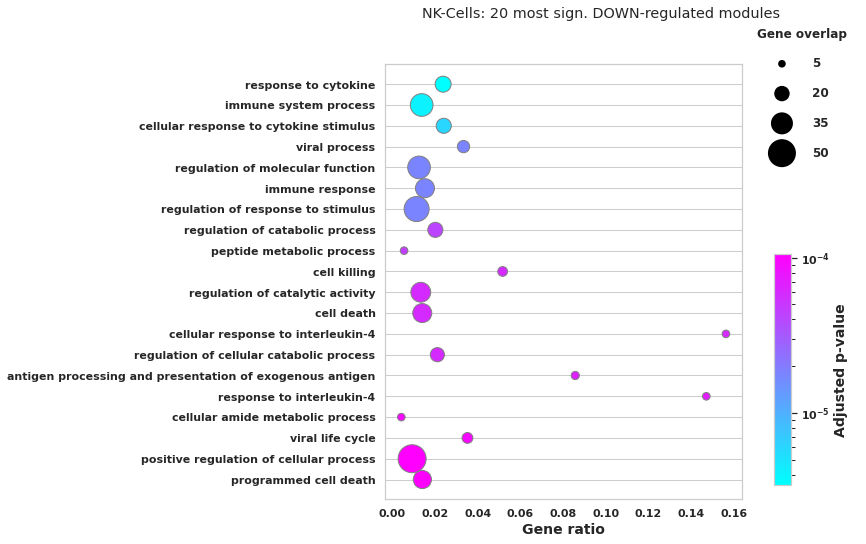

Of the total 
2963
terms, there are 
2963 different GO:BP groups 


In [39]:
enr_down = gprofiler_custom_LISA.gprofiler_enrich(
    genes_down_nk_code,
    n_modules_to_plot=20,
    ordered=True,
    sources=["GO:BP"],
    title="NK-Cells: 20 most sign. DOWN-regulated modules",
)

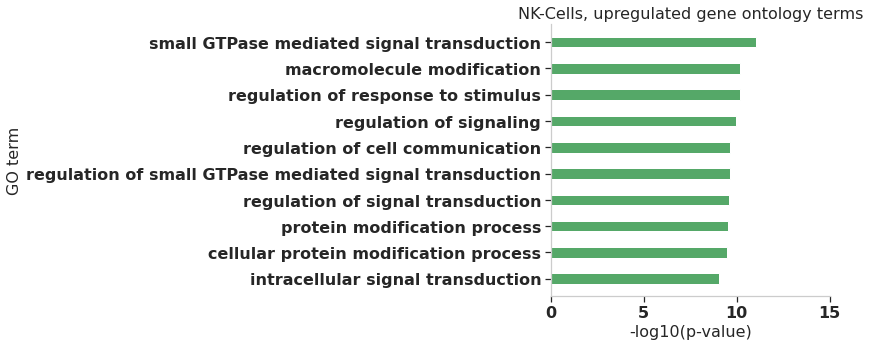

In [40]:
fz = 16
with plt.rc_context(
    {
        "figure.figsize": (5, 5),
        "xtick.labelsize": fz,
        "ytick.labelsize": fz,
        "legend.title_fontsize": "xx-large",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "xtick.bottom": True,
        "ytick.left": True,
    }
):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.barh(
        y=enr_up.name[:10],
        width=-np.log10(enr_up.p_value[:10][::-1]),
        height=0.4,
        color="g",
    )
    plt.xlabel("-log10(p-value)", fontsize=fz)
    plt.ylabel("GO term", fontsize=fz)
    plt.title(f"NK-Cells, upregulated gene ontology terms", fontsize=fz)
    plt.xlim((0, 15))
    plt.grid(None)
    plt.show()

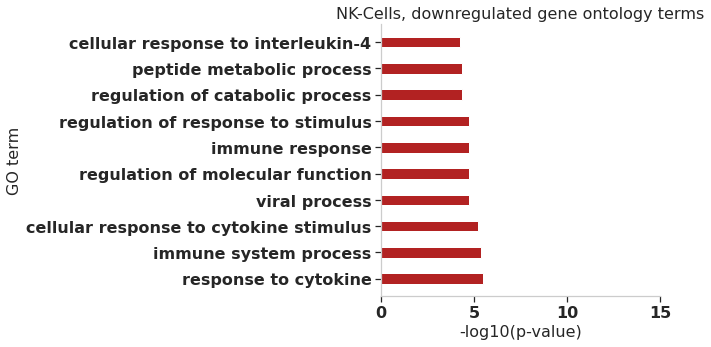

In [41]:
fz = 16
with plt.rc_context(
    {
        "figure.figsize": (5, 5),
        "xtick.labelsize": fz,
        "ytick.labelsize": fz,
        "legend.title_fontsize": "xx-large",
        "axes.spines.right": False,
        "axes.spines.top": False,
        "xtick.bottom": True,
        "ytick.left": True,
    }
):
    y = enr_down.name[:10].copy()
    # shorten label:
    for row, val in enumerate(enr_down.name[:10]):
        if (
            val
            == "antigen processing and presentation of exogenous peptide antigen via MHC class I, TAP-dependent"
        ):
            y[
                row
            ] = "antigen processing and presentation of exogenous\npeptide antigen via MHC class I, TAP-dependent"
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.barh(
        y=y,
        width=-np.log10(enr_down.p_value[:10]),
        height=0.4,
        color="firebrick",
    )
    plt.xlabel("-log10(p-value)", fontsize=fz)
    plt.ylabel("GO term", fontsize=fz)
    plt.title(f"NK-Cells, downregulated gene ontology terms", fontsize=fz)
    plt.xlim((0, 15))
    plt.grid(None)
    plt.show()

In [134]:
sc.logging.print_versions()


The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.8
scanpy      1.8.2
sinfo       0.3.4
-----
PIL                                         8.4.0
aa8f2297d25b4dc6fd3d98411eb3ba53823c4f42    NA
absl                                        NA
anndata2ri                                  1.0.6
anyio                                       NA
asciitree                                   NA
astunparse                                  1.6.3
attr                                        21.2.0
babel                                       2.9.1
backcall  